In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
import warnings

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Dataset IDs and Official NYC Open Data API

HOUSING_ID = "ygpa-z7cr"
TRANSPORT_ID = "xeqp-qz8h"

BASE_URL = "https://data.cityofnewyork.us/resource/{}.csv"

housing_url = BASE_URL.format(HOUSING_ID)
transport_url = BASE_URL.format(TRANSPORT_ID)

print("Housing dataset:", housing_url)
print("Transportation dataset:", transport_url)


Housing dataset: https://data.cityofnewyork.us/resource/ygpa-z7cr.csv
Transportation dataset: https://data.cityofnewyork.us/resource/xeqp-qz8h.csv


In [3]:

# Step 3: Load Both Datasets

import requests
from io import StringIO

def load_nyc_dataset(url, limit):
    params = {
        "$limit": limit,
        "$order": ":id"
    }

    response = requests.get(url, params=params, timeout=180)
    response.raise_for_status()

    return pd.read_csv(StringIO(response.text), low_memory=False)

# Load a sample of housing complaints
df_housing = load_nyc_dataset(housing_url, 100000)

# Load all available SIRTA records (within the API limit)
df_transport = load_nyc_dataset(transport_url, 50000)

print("Housing shape:", df_housing.shape)
print("Transportation shape:", df_transport.shape)


Housing shape: (100000, 33)
Transportation shape: (13754, 23)


In [4]:

# Step 4: Dataset Structure

print("=" * 60)
print("HOUSING DATASET")
print("=" * 60)

print("Rows:", len(df_housing))
print("Columns:", len(df_housing.columns))
print("\nColumn names:")
print(df_housing.columns.tolist())

print("\nFirst 5 records:")
display(df_housing.head())

print("\n" + "=" * 60)
print("TRANSPORTATION DATASET")
print("=" * 60)

print("Rows:", len(df_transport))
print("Columns:", len(df_transport.columns))
print("\nColumn names:")
print(df_transport.columns.tolist())

print("\nFirst 5 records:")
display(df_transport.head())


HOUSING DATASET
Rows: 100000
Columns: 33

Column names:
['received_date', 'problem_id', 'complaint_id', 'building_id', 'borough', 'house_number', 'street_name', 'post_code', 'block', 'lot', 'apartment', 'community_board', 'unit_type', 'space_type', 'type', 'major_category', 'minor_category', 'problem_code', 'complaint_status', 'complaint_status_date', 'problem_status', 'problem_status_date', 'status_description', 'problem_duplicate_flag', 'complaint_anonymous_flag', 'unique_key', 'latitude', 'longitude', 'council_district', 'census_tract', 'bin', 'bbl', 'nta']

First 5 records:


,received_date,problem_id,complaint_id,building_id,borough,house_number,street_name,post_code,block,lot,apartment,community_board,unit_type,space_type,type,major_category,minor_category,problem_code,complaint_status,complaint_status_date,problem_status,problem_status_date,status_description,problem_duplicate_flag,complaint_anonymous_flag,unique_key,latitude,longitude,council_district,census_tract,bin,bbl,nta
0,2016-11-14T13:16:19.000,16957421,8206660,58969,BRONX,652,COURTLANDT AVENUE,10451.0,2399,6,3H,1,APARTMENT,BATHROOM,EMERGENCY,PLUMBING,BATHTUB/SHOWER,BROKEN OR MISSING,CLOSE,2016-12-02T05:20:39.000,CLOSE,2016-12-01T14:16:06.000,The Department of Housing Preservation and Dev...,N,N,34775301.0,40.819038,-73.918410,17.0,67.0,2001672.0,2.023990e+09,Melrose
1,2016-11-14T13:16:19.000,16957422,8206660,58969,BRONX,652,COURTLANDT AVENUE,10451.0,2399,6,3H,1,APARTMENT,BATHROOM,NON EMERGENCY,PLUMBING,BATHTUB/SHOWER,CHIPPED OR RUSTED,CLOSE,2016-12-02T05:20:39.000,CLOSE,2016-12-01T14:16:07.000,The Department of Housing Preservation and Dev...,N,N,34774219.0,40.819038,-73.918410,17.0,67.0,2001672.0,2.023990e+09,Melrose
2,2016-11-14T13:16:19.000,16957423,8206660,58969,BRONX,652,COURTLANDT AVENUE,10451.0,2399,6,3H,1,APARTMENT,BEDROOM,NON EMERGENCY,PAINT/PLASTER,WALL,CHIPPED/PEELING/FLAKING,CLOSE,2016-12-02T05:20:39.000,CLOSE,2016-12-01T14:16:07.000,The Department of Housing Preservation and Dev...,N,N,34776231.0,40.819038,-73.918410,17.0,67.0,2001672.0,2.023990e+09,Melrose
3,2016-12-06T22:49:59.000,17056510,8272386,811407,QUEENS,89-21,ELMHURST AVENUE,11373.0,1511,1,BLDG,4,BUILDING-WIDE,BUILDING-WIDE,EMERGENCY,HEAT/HOT WATER,ENTIRE BUILDING,NO HEAT,CLOSE,2016-12-08T05:21:18.000,CLOSE,2016-12-07T21:48:44.000,More than one complaint was received for this ...,Y,Y,34946314.0,40.747421,-73.876853,21.0,27102.0,4431449.0,4.015110e+09,Elmhurst
4,2017-02-23T15:37:51.000,17317874,8417713,27323,MANHATTAN,644,RIVERSIDE DRIVE,10031.0,2088,114,BLDG,9,BUILDING-WIDE,BUILDING-WIDE,EMERGENCY,HEAT/HOT WATER,ENTIRE BUILDING,NO HEAT AND NO HOT WATER,CLOSE,2017-03-01T05:20:43.000,CLOSE,2017-02-28T11:37:39.000,More than one complaint was received for this ...,Y,Y,35561050.0,40.825120,-73.953892,7.0,225.0,1062334.0,1.020880e+09,Hamilton Heights-Sugar Hill



TRANSPORTATION DATASET
Rows: 13754
Columns: 23

Column names:
['open_data_crash_id', 'crash_date', 'crash_time', 'crash_police_precinct', 'crash_borough', 'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities', 'latitude', 'longitude', 'on_street', 'cross_street', 'address', 'highway_reference_marker', 'zipcode', 'similar_fatalities_severe', 'similar_fatalities_all', 'community_board', 'council_district', 'bin', 'bbl', 'census_tract_2020_', 'neighborhood_tabulation_area_nta_2020_']

First 5 records:


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,address,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,2022-01-01T00:00:00.000,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,2022-01-01T00:00:00.000,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

# Step 5: Data Types

print("HOUSING DATA TYPES")
display(df_housing.dtypes.to_frame("Data Type"))

print("\nTRANSPORTATION DATA TYPES")
display(df_transport.dtypes.to_frame("Data Type"))


HOUSING DATA TYPES


,Data Type
received_date,object
problem_id,int64
complaint_id,int64
building_id,int64
borough,object
house_number,object
street_name,object
post_code,float64
block,int64
lot,int64



TRANSPORTATION DATA TYPES


,Data Type
open_data_crash_id,float64
crash_date,object
crash_time,object
crash_police_precinct,float64
crash_borough,object
total_non_severe_injuries,float64
total_severe_injuries,float64
total_fatalities,float64
latitude,float64
longitude,float64


In [6]:

# Step 6: Missing Values Analysis

housing_missing = pd.DataFrame({
    "Missing Values": df_housing.isnull().sum(),
    "Missing Percentage": df_housing.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

transport_missing = pd.DataFrame({
    "Missing Values": df_transport.isnull().sum(),
    "Missing Percentage": df_transport.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

print("HOUSING MISSING VALUES")
display(housing_missing)

print("TRANSPORTATION MISSING VALUES")
display(transport_missing)


HOUSING MISSING VALUES


,Missing Values,Missing Percentage
unique_key,7777,7.777
problem_code,1236,1.236
bbl,193,0.193
bin,193,0.193
apartment,127,0.127
post_code,102,0.102
council_district,41,0.041
census_tract,41,0.041
latitude,41,0.041
nta,41,0.041


TRANSPORTATION MISSING VALUES


,Missing Values,Missing Percentage
highway_reference_marker,12702,92.351316
address,11177,81.263632
bin,10967,79.736804
bbl,10967,79.736804
census_tract_2020_,9886,71.877272
neighborhood_tabulation_area_nta_2020_,9886,71.877272
council_district,9883,71.855460
community_board,9883,71.855460
zipcode,5682,41.311618
cross_street,5642,41.020794


In [7]:

# Step 7: Duplicate Analysis

print("Housing duplicate rows:", df_housing.duplicated().sum())
print("Transportation duplicate rows:", df_transport.duplicated().sum())

if "problem_id" in df_housing.columns:
    print("Duplicate housing problem IDs:",
          df_housing["problem_id"].duplicated().sum())

if "open_data_crash_id" in df_transport.columns:
    print("Duplicate crash IDs:",
          df_transport["open_data_crash_id"].duplicated().sum())


Housing duplicate rows: 0
Transportation duplicate rows: 3
Duplicate housing problem IDs: 0
Duplicate crash IDs: 444


In [8]:

# Step 8: Check Required Integration Attributes

print("HOUSING COLUMNS")
for col in ["received_date", "post_code", "borough", "problem_id"]:
    print(col, ":", col in df_housing.columns)

print("\nTRANSPORTATION COLUMNS")
for col in ["crash_date", "zipcode", "crash_borough",
            "open_data_crash_id", "total_severe_injuries",
            "total_fatalities"]:
    print(col, ":", col in df_transport.columns)


HOUSING COLUMNS
received_date : True
post_code : True
borough : True
problem_id : True

TRANSPORTATION COLUMNS
crash_date : True
zipcode : True
crash_borough : True
open_data_crash_id : True
total_severe_injuries : True
total_fatalities : True


In [9]:

# Step 9: Descriptive Statistics

print("HOUSING STATISTICS")
display(df_housing.describe(include="all").T)

print("\nTRANSPORTATION STATISTICS")
display(df_transport.describe(include="all").T)


HOUSING STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
received_date,100000,51465,2023-05-02T13:59:34.000,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
problem_id,100000.0,NaN,NaN,NaN,13253389.95729,5854417.929474,3515587.0,10035546.75,10072657.5,10108692.25,24116760.0
complaint_id,100000.0,NaN,NaN,NaN,6685494.21355,2953326.129849,2279555.0,5064719.75,5080927.0,5095863.0,12176627.0
building_id,100000.0,NaN,NaN,NaN,271617.11782,262566.367222,3.0,61059.75,185343.0,374562.0,1017603.0
borough,100000,5,BROOKLYN,35615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
house_number,100000,6026,160,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_name,100000,2791,GRAND CONCOURSE,1373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_code,99898.0,NaN,NaN,NaN,10750.681645,513.942176,2018.0,10452.0,10469.0,11224.0,11697.0
block,100000.0,NaN,NaN,NaN,3531.20299,2574.681295,0.0,1947.0,2949.0,4630.0,16350.0
lot,100000.0,NaN,NaN,NaN,232.88953,1171.409814,0.0,16.0,35.0,58.0,9100.0



TRANSPORTATION STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
open_data_crash_id,13310.0,NaN,NaN,NaN,7271532.868295,11289301.231011,2126022.0,4612503.25,4718837.5,4814222.75,121326075.0
crash_date,13310,1641,2022-05-21T00:00:00.000,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_time,13310,1728,00:00,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_police_precinct,13310.0,NaN,NaN,NaN,67.837866,34.683947,1.0,42.0,68.0,104.0,123.0
crash_borough,13255,5,Brooklyn,3954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_non_severe_injuries,13310.0,NaN,NaN,NaN,0.270473,0.836031,0.0,0.0,0.0,0.0,19.0
total_severe_injuries,13310.0,NaN,NaN,NaN,1.011495,0.451514,0.0,1.0,1.0,1.0,7.0
total_fatalities,13310.0,NaN,NaN,NaN,0.082795,0.294304,0.0,0.0,0.0,0.0,5.0
latitude,10868.0,NaN,NaN,NaN,40.730641,0.083378,40.499672,40.667854,40.72671,40.800663,40.912468
longitude,10868.0,NaN,NaN,NaN,-73.921537,0.081929,-74.24857,-73.96879,-73.923693,-73.874742,-73.7006


In [10]:

# Step 10: Date Range Analysis

df_housing["received_date"] = pd.to_datetime(
    df_housing["received_date"], errors="coerce"
)

df_transport["crash_date"] = pd.to_datetime(
    df_transport["crash_date"], errors="coerce"
)

print("HOUSING DATE RANGE")
print("Earliest:", df_housing["received_date"].min())
print("Latest:", df_housing["received_date"].max())

print("\nTRANSPORTATION DATE RANGE")
print("Earliest:", df_transport["crash_date"].min())
print("Latest:", df_transport["crash_date"].max())


HOUSING DATE RANGE
Earliest: 2004-02-05 14:24:18
Latest: 2023-05-19 00:04:50

TRANSPORTATION DATE RANGE
Earliest: 2022-01-01 00:00:00
Latest: 2026-06-30 00:00:00


In [11]:

# Step 11: Geographic Coverage

print("HOUSING")
print("Unique ZIP codes:",
      df_housing["post_code"].nunique())
print("Missing ZIP codes:",
      df_housing["post_code"].isna().sum())

print("\nTRANSPORTATION")
print("Unique ZIP codes:",
      df_transport["zipcode"].nunique())
print("Missing ZIP codes:",
      df_transport["zipcode"].isna().sum())

print("\nHousing boroughs:")
display(df_housing["borough"].value_counts(dropna=False))

print("\nTransportation boroughs:")
display(df_transport["crash_borough"].value_counts(dropna=False))


HOUSING
Unique ZIP codes: 177
Missing ZIP codes: 102

TRANSPORTATION
Unique ZIP codes: 187
Missing ZIP codes: 5682

Housing boroughs:


,count
borough,
BROOKLYN,35615
BRONX,30475
MANHATTAN,20035
QUEENS,11741
STATEN ISLAND,2134



Transportation boroughs:


,count
crash_borough,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
NaN,499


In [ ]:

# Step 13: Verify Full Housing Dataset Date Coverage

def get_api_data(dataset_id, params):
    url = f"https://data.cityofnewyork.us/resource/{dataset_id}.json"
    response = requests.get(url, params=params, timeout=180)
    response.raise_for_status()
    return response.json()

housing_dates = get_api_data(
    HOUSING_ID,
    {
        "$select": "min(received_date) as earliest_date, max(received_date) as latest_date, count(*) as total_records",
    }
)

transport_dates = get_api_data(
    TRANSPORT_ID,
    {
        "$select": "min(crash_date) as earliest_date, max(crash_date) as latest_date, count(*) as total_records",
    }
)

print("FULL HOUSING DATASET")
display(pd.DataFrame(housing_dates))

print("\nFULL TRANSPORTATION DATASET")
display(pd.DataFrame(transport_dates))


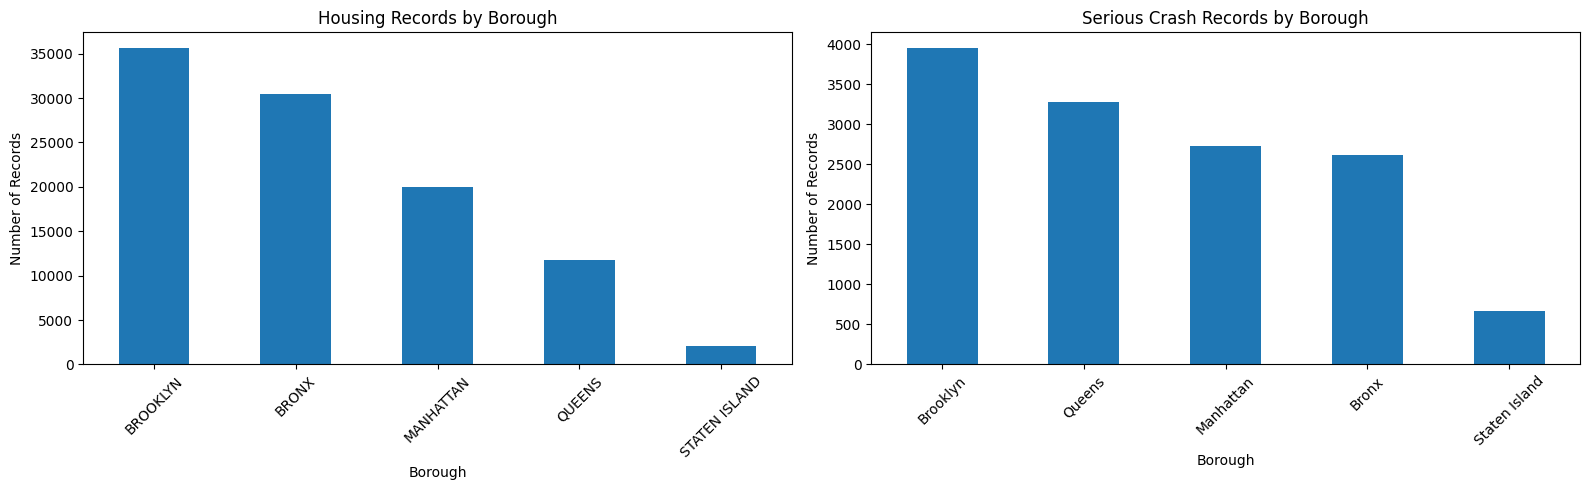

In [12]:

# Step 12: Initial Dataset Visualizations

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_housing["borough"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Housing Records by Borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=45)

df_transport["crash_borough"].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Serious Crash Records by Borough")
axes[1].set_xlabel("Borough")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [14]:

# Step 13: Fast Dataset Date Coverage Check

def get_api_data(dataset_id, params):
    url = f"https://data.cityofnewyork.us/resource/{dataset_id}.json"

    response = requests.get(
        url,
        params=params,
        timeout=(10, 45)
    )

    response.raise_for_status()
    return response.json()


try:
    housing_dates = get_api_data(
        HOUSING_ID,
        {
            "$select": "min(received_date), max(received_date), count(*)"
        }
    )

    print("FULL HOUSING DATASET")
    display(pd.DataFrame(housing_dates))

except Exception as e:
    print("Housing API request failed:", e)


try:
    transport_dates = get_api_data(
        TRANSPORT_ID,
        {
            "$select": "min(crash_date), max(crash_date), count(*)"
        }
    )

    print("FULL TRANSPORTATION DATASET")
    display(pd.DataFrame(transport_dates))

except Exception as e:
    print("Transportation API request failed:", e)


FULL HOUSING DATASET


,min_received_date,max_received_date,count
0,2001-12-16T10:30:00.000,2026-11-08T00:07:51.000,16450245


FULL TRANSPORTATION DATASET


,min_crash_date,max_crash_date,count
0,2022-01-01T00:00:00.000,2026-06-30T00:00:00.000,13754


In [15]:

# Step 14: Housing Records During 2022–2023

overlap_housing = get_api_data(
    HOUSING_ID,
    {
        "$select": "date_extract_y(received_date) as year, count(*) as records",
        "$where": "received_date >= '2022-01-01T00:00:00' AND received_date < '2023-05-20T00:00:00'",
        "$group": "year"
    }
)

display(pd.DataFrame(overlap_housing))


,year,records
0,2022,733471
1,2023,289615


In [16]:

# Step 15: Traffic Crash Severity Analysis

severity_columns = [
    "total_non_severe_injuries",
    "total_severe_injuries",
    "total_fatalities"
]

display(df_transport[severity_columns].describe())

print("\nMissing values:")
display(df_transport[severity_columns].isnull().sum())

print("\nTotal recorded injuries and fatalities:")
display(df_transport[severity_columns].sum())


,total_non_severe_injuries,total_severe_injuries,total_fatalities
count,13310.000000,13310.000000,13310.000000
mean,0.270473,1.011495,0.082795
std,0.836031,0.451514,0.294304
min,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000
50%,0.000000,1.000000,0.000000
75%,0.000000,1.000000,0.000000
max,19.000000,7.000000,5.000000



Missing values:


,0
total_non_severe_injuries,444
total_severe_injuries,444
total_fatalities,444



Total recorded injuries and fatalities:


,0
total_non_severe_injuries,3600.0
total_severe_injuries,13463.0
total_fatalities,1102.0


In [17]:

# Step 16: Geographic Data Quality

geo_columns = [
    "zipcode",
    "crash_borough",
    "latitude",
    "longitude",
    "community_board",
    "census_tract_2020_",
    "neighborhood_tabulation_area_nta_2020_"
]

available_geo_columns = [
    col for col in geo_columns if col in df_transport.columns
]

geo_quality = pd.DataFrame({
    "Missing": df_transport[available_geo_columns].isnull().sum(),
    "Available": df_transport[available_geo_columns].notnull().sum(),
    "Missing Percentage":
        df_transport[available_geo_columns].isnull().mean() * 100
})

display(geo_quality)


,Missing,Available,Missing Percentage
zipcode,5682,8072,41.311618
crash_borough,499,13255,3.628035
latitude,2886,10868,20.982987
longitude,2886,10868,20.982987
community_board,9883,3871,71.855460
census_tract_2020_,9886,3868,71.877272
neighborhood_tabulation_area_nta_2020_,9886,3868,71.877272


In [18]:

# Step 17: Standardize ZIP Codes and Borough Names

def clean_zip(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
        .replace(["<NA>", "nan", "None", "00000"], pd.NA)
    )

df_housing["zip_clean"] = clean_zip(df_housing["post_code"])
df_transport["zip_clean"] = clean_zip(df_transport["zipcode"])

df_housing["borough_clean"] = (
    df_housing["borough"].astype("string").str.strip().str.upper()
)

df_transport["borough_clean"] = (
    df_transport["crash_borough"].astype("string").str.strip().str.upper()
)

print("Housing standardized ZIP examples:")
display(df_housing[["post_code", "zip_clean", "borough_clean"]].head())

print("\nTransportation standardized ZIP examples:")
display(df_transport[["zipcode", "zip_clean", "borough_clean"]].head())


Housing standardized ZIP examples:


,post_code,zip_clean,borough_clean
0,10451.0,10451,BRONX
1,10451.0,10451,BRONX
2,10451.0,10451,BRONX
3,11373.0,11373,QUEENS
4,10031.0,10031,MANHATTAN



Transportation standardized ZIP examples:


,zipcode,zip_clean,borough_clean
0,NaN,<NA>,BRONX
1,NaN,<NA>,BRONX
2,NaN,<NA>,BRONX
3,NaN,<NA>,BRONX
4,NaN,<NA>,BRONX


In [19]:

# Step 18: ZIP Code Integration Feasibility

housing_zips = set(df_housing["zip_clean"].dropna().unique())
transport_zips = set(df_transport["zip_clean"].dropna().unique())

common_zips = housing_zips.intersection(transport_zips)

print("Housing ZIP codes:", len(housing_zips))
print("Transportation ZIP codes:", len(transport_zips))
print("Common ZIP codes:", len(common_zips))

print("\nSample matching ZIP codes:")
print(sorted(common_zips)[:30])

print("\nZIP codes only in housing:", len(housing_zips - transport_zips))
print("ZIP codes only in transportation:", len(transport_zips - housing_zips))


Housing ZIP codes: 177
Transportation ZIP codes: 187
Common ZIP codes: 172

Sample matching ZIP codes:
['10001', '10002', '10003', '10005', '10006', '10007', '10009', '10010', '10011', '10012', '10013', '10014', '10016', '10017', '10018', '10019', '10021', '10022', '10023', '10024', '10025', '10026', '10027', '10028', '10029', '10030', '10031', '10032', '10033', '10034']

ZIP codes only in housing: 5
ZIP codes only in transportation: 15


In [23]:

#Step 19: Reliable NYC API Function

import time
import requests
import pandas as pd
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session.mount("https://", HTTPAdapter(max_retries=retry_strategy))


def get_api_data(dataset_id, params, timeout=180):
    url = f"https://data.cityofnewyork.us/resource/{dataset_id}.json"

    response = session.get(
        url,
        params=params,
        timeout=(15, timeout)
    )

    response.raise_for_status()
    return response.json()

print("API extraction function ready.")


API extraction function ready.


In [24]:

#  Step 20: Monthly Housing Aggregation

housing_monthly_results = []

months = pd.date_range(
    start="2022-01-01",
    end="2026-06-01",
    freq="MS"
)

for i, month in enumerate(months, start=1):

    next_month = month + pd.DateOffset(months=1)

    params = {
        "$select": """
            post_code,
            count(*) as problem_records,
            count(distinct complaint_id) as unique_complaints
        """,
        "$where": (
            f"received_date >= '{month:%Y-%m-%d}T00:00:00' "
            f"AND received_date < '{next_month:%Y-%m-%d}T00:00:00' "
            "AND post_code IS NOT NULL"
        ),
        "$group": "post_code",
        "$limit": 5000
    }

    try:
        result = get_api_data(HOUSING_ID, params)

        for row in result:
            row["year"] = month.year
            row["month"] = month.month

        housing_monthly_results.extend(result)

        print(
            f"[{i}/{len(months)}] "
            f"{month:%B %Y}: {len(result)} ZIP groups"
        )

    except Exception as e:
        print(f"FAILED: {month:%B %Y} - {e}")
        raise

df_housing_agg = pd.DataFrame(housing_monthly_results)

print("\nHousing aggregation completed.")
print("Shape:", df_housing_agg.shape)

display(df_housing_agg.head())


[1/54] January 2022: 182 ZIP groups
[2/54] February 2022: 178 ZIP groups
[3/54] March 2022: 178 ZIP groups
[4/54] April 2022: 176 ZIP groups
[5/54] May 2022: 176 ZIP groups
[6/54] June 2022: 177 ZIP groups
[7/54] July 2022: 178 ZIP groups
[8/54] August 2022: 176 ZIP groups
[9/54] September 2022: 179 ZIP groups
[10/54] October 2022: 182 ZIP groups
[11/54] November 2022: 181 ZIP groups
[12/54] December 2022: 181 ZIP groups
[13/54] January 2023: 179 ZIP groups
[14/54] February 2023: 180 ZIP groups
[15/54] March 2023: 179 ZIP groups
[16/54] April 2023: 176 ZIP groups
[17/54] May 2023: 175 ZIP groups
[18/54] June 2023: 178 ZIP groups
[19/54] July 2023: 180 ZIP groups
[20/54] August 2023: 178 ZIP groups
[21/54] September 2023: 180 ZIP groups
[22/54] October 2023: 184 ZIP groups
[23/54] November 2023: 182 ZIP groups
[24/54] December 2023: 183 ZIP groups
[25/54] January 2024: 184 ZIP groups
[26/54] February 2024: 178 ZIP groups
[27/54] March 2024: 180 ZIP groups
[28/54] April 2024: 179 ZIP gro

,post_code,problem_records,unique_complaints,year,month
0,10001,142,98,2022,1
1,10002,829,589,2022,1
2,10003,548,381,2022,1
3,10005,20,6,2022,1
4,10006,9,9,2022,1


In [28]:
# Restore the full transportation dataset

transport_data = get_api_data(
    TRANSPORT_ID,
    {
        "$limit": 50000,
        "$order": "crash_date"
    }
)

df_transport_full = pd.DataFrame(transport_data)

print("Transportation dataset restored!")
print("Rows:", len(df_transport_full))
print("Columns:", len(df_transport_full.columns))

display(df_transport_full.head())

Transportation dataset restored!
Rows: 13754
Columns: 23


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,similar_fatalities_severe,similar_fatalities_all,address,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_,highway_reference_marker,zipcode
0,4492364,2022-01-01T00:00:00.000,01:28,46,Bronx,1,1,0,40.8587070,-73.9037000,JEROME AVENUE,EAST 183 STREET,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159,2022-01-01T00:00:00.000,04:33,46,Bronx,0,1,0,NaN,NaN,JEROME AVENUE,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487,2022-01-01T00:00:00.000,05:55,47,Bronx,0,1,0,40.8715500,-73.8642800,NaN,NaN,0,0,3207 WALLACE AVENUE,212,12,2056281,2045980025,372,BX1201,NaN,NaN
3,4491223,2022-01-01T00:00:00.000,10:42,43,Bronx,0,1,0,40.8236730,-73.8723300,BRONX RIVER PARKWAY,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,907HX1M11001,NaN
4,4491418,2022-01-01T00:00:00.000,20:55,49,Bronx,0,1,0,40.8639450,-73.8645200,BOSTON ROAD,WALLACE AVENUE,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
# Create transportation aggregation

df_transport_full["crash_date"] = pd.to_datetime(
    df_transport_full["crash_date"],
    errors="coerce"
)

df_transport_full["zipcode"] = clean_zip(
    df_transport_full["zipcode"]
)

df_transport_full["year"] = df_transport_full["crash_date"].dt.year
df_transport_full["month"] = df_transport_full["crash_date"].dt.month

severity_columns = [
    "total_non_severe_injuries",
    "total_severe_injuries",
    "total_fatalities"
]

for col in severity_columns:
    df_transport_full[col] = pd.to_numeric(
        df_transport_full[col],
        errors="coerce"
    )

# Keep the shared analysis period
df_transport_full = df_transport_full[
    df_transport_full["crash_date"].between(
        "2022-01-01", "2026-06-30"
    )
].copy()

# Aggregate by ZIP code, year, and month
df_transport_agg = (
    df_transport_full
    .dropna(subset=["zipcode", "year", "month"])
    .groupby(["zipcode", "year", "month"])
    .agg(
        serious_crashes=("open_data_crash_id", "nunique"),
        non_severe_injuries=(
            "total_non_severe_injuries",
            lambda x: x.sum(min_count=1)
        ),
        severe_injuries=(
            "total_severe_injuries",
            lambda x: x.sum(min_count=1)
        ),
        fatalities=(
            "total_fatalities",
            lambda x: x.sum(min_count=1)
        ),
        severity_records=("total_severe_injuries", "count")
    )
    .reset_index()
)

print("Transportation aggregation created successfully!")
print("Rows:", len(df_transport_agg))
display(df_transport_agg.head())

Transportation aggregation created successfully!
Rows: 4434


,zipcode,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records
0,10000,2022.0,10.0,1,0.0,1.0,0.0,1
1,10000,2023.0,5.0,1,0.0,1.0,0.0,1
2,10000,2023.0,6.0,1,0.0,1.0,0.0,1
3,10000,2023.0,8.0,1,0.0,1.0,0.0,1
4,10000,2024.0,1.0,1,4.0,1.0,0.0,1


In [32]:
# Step 21: Standardize and Validate Integration Keys

# 1. Standardize ZIP codes
df_housing_agg["zip_clean"] = clean_zip(
    df_housing_agg["post_code"]
)

df_transport_agg["zip_clean"] = clean_zip(
    df_transport_agg["zipcode"]
)

# 2. Standardize year and month
for df in [df_housing_agg, df_transport_agg]:
    df["year"] = pd.to_numeric(
        df["year"], errors="coerce"
    ).astype("Int64")

    df["month"] = pd.to_numeric(
        df["month"], errors="coerce"
    ).astype("Int64")

# 3. Convert housing measures to numeric
numeric_housing = [
    "problem_records",
    "unique_complaints"
]

for col in numeric_housing:
    df_housing_agg[col] = pd.to_numeric(
        df_housing_agg[col], errors="coerce"
    )

# 4. Convert transportation measures to numeric
numeric_transport = [
    "serious_crashes",
    "non_severe_injuries",
    "severe_injuries",
    "fatalities",
    "severity_records"
]

for col in numeric_transport:
    df_transport_agg[col] = pd.to_numeric(
        df_transport_agg[col], errors="coerce"
    )

# 5. Validate integration keys
keys = ["zip_clean", "year", "month"]

print("HOUSING DATA")
print("Rows:", len(df_housing_agg))
print("Missing integration keys:")
display(df_housing_agg[keys].isna().sum())
print("Duplicate integration keys:",
      df_housing_agg.duplicated(keys).sum())

print("\nTRANSPORTATION DATA")
print("Rows:", len(df_transport_agg))
print("Missing integration keys:")
display(df_transport_agg[keys].isna().sum())
print("Duplicate integration keys:",
      df_transport_agg.duplicated(keys).sum())

# 6. Display samples
print("\nHousing aggregation:")
display(df_housing_agg.head())

print("\nTransportation aggregation:")
display(df_transport_agg.head())

HOUSING DATA
Rows: 9695
Missing integration keys:


,0
zip_clean,1
year,0
month,0


Duplicate integration keys: 0

TRANSPORTATION DATA
Rows: 4434
Missing integration keys:


,0
zip_clean,0
year,0
month,0


Duplicate integration keys: 0

Housing aggregation:


,post_code,problem_records,unique_complaints,year,month,zip_clean
0,10001,142,98,2022,1,10001
1,10002,829,589,2022,1,10002
2,10003,548,381,2022,1,10003
3,10005,20,6,2022,1,10005
4,10006,9,9,2022,1,10006



Transportation aggregation:


,zipcode,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,zip_clean
0,10000,2022,10,1,0.0,1.0,0.0,1,10000
1,10000,2023,5,1,0.0,1.0,0.0,1,10000
2,10000,2023,6,1,0.0,1.0,0.0,1,10000
3,10000,2023,8,1,0.0,1.0,0.0,1,10000
4,10000,2024,1,1,4.0,1.0,0.0,1,10000


In [33]:
# Step 22: Check ZIP Code Compatibility

housing_zips = set(
    df_housing_agg["zip_clean"].dropna().unique()
)

transport_zips = set(
    df_transport_agg["zip_clean"].dropna().unique()
)

common_zips = housing_zips.intersection(transport_zips)

housing_only = housing_zips - transport_zips
transport_only = transport_zips - housing_zips

print("HOUSING ZIP CODES:", len(housing_zips))
print("TRANSPORTATION ZIP CODES:", len(transport_zips))
print("COMMON ZIP CODES:", len(common_zips))
print("HOUSING-ONLY ZIP CODES:", len(housing_only))
print("TRANSPORTATION-ONLY ZIP CODES:", len(transport_only))

print("\nTransportation records using ZIP 10000:")
display(
    df_transport_agg[
        df_transport_agg["zip_clean"] == "10000"
    ]
)

print("\nTransportation-only ZIP codes:")
print(sorted(transport_only))

print("\nHousing records with missing ZIP:")
display(
    df_housing_agg[
        df_housing_agg["zip_clean"].isna()
    ]
)

HOUSING ZIP CODES: 219
TRANSPORTATION ZIP CODES: 187
COMMON ZIP CODES: 182
HOUSING-ONLY ZIP CODES: 37
TRANSPORTATION-ONLY ZIP CODES: 5

Transportation records using ZIP 10000:


,zipcode,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,zip_clean
0,10000,2022,10,1,0.0,1.0,0.0,1,10000
1,10000,2023,5,1,0.0,1.0,0.0,1,10000
2,10000,2023,6,1,0.0,1.0,0.0,1,10000
3,10000,2023,8,1,0.0,1.0,0.0,1,10000
4,10000,2024,1,1,4.0,1.0,0.0,1,10000
5,10000,2025,3,1,0.0,1.0,0.0,1,10000
6,10000,2025,4,5,2.0,5.0,0.0,5,10000
7,10000,2025,5,4,2.0,4.0,0.0,4,10000
8,10000,2025,6,4,1.0,3.0,1.0,4,10000
9,10000,2025,7,5,1.0,6.0,0.0,5,10000



Transportation-only ZIP codes:
['10111', '10168', '10170', '10281', '11251']

Housing records with missing ZIP:


,post_code,problem_records,unique_complaints,year,month,zip_clean
2144,0,1,1,2023,1,<NA>


In [34]:
# Step 23: Investigate ZIP 10000 in Both Datasets

print("TRANSPORTATION SOURCE RECORDS — ZIP 10000")

display(
    df_transport_full[
        df_transport_full["zipcode"] == "10000"
    ][[
        "crash_date",
        "crash_borough",
        "zipcode",
        "address",
        "on_street",
        "latitude",
        "longitude"
    ]].head(20)
)

print("\nHOUSING AGGREGATED RECORDS — ZIP 10000")

display(
    df_housing_agg[
        df_housing_agg["zip_clean"] == "10000"
    ].head(20)
)

TRANSPORTATION SOURCE RECORDS — ZIP 10000


,crash_date,crash_borough,zipcode,address,on_street,latitude,longitude
2342,2022-10-26,Manhattan,10000,NaN,WEST DRIVE,40.7715380,-73.9774200
3814,2023-05-16,Manhattan,10000,1 TRANSVERSE ROAD NUMBER ONE,NaN,40.76871,-73.969986
4127,2023-06-18,Manhattan,10000,26 TRANSVERSE ROAD NUMBER THREE,NaN,40.781506,-73.962685
4630,2023-08-10,Manhattan,10000,1 TRANSVERSE ROAD NUMBER TWO,NaN,40.77712,-73.96395
5985,2024-01-13,Manhattan,10000,1 TRANSVERSE ROAD NUMBER TWO,NaN,40.77712,-73.96395
9588,2025-03-30,Manhattan,10000,105-01 EAST DR,NaN,NaN,NaN
9639,2025-04-06,Manhattan,10000,107-01 EAST DR,NaN,NaN,NaN
9692,2025-04-14,Manhattan,10000,103-02 WEST DR,NaN,NaN,NaN
9746,2025-04-22,Manhattan,10000,76-01 WEST DR,NaN,NaN,NaN
9764,2025-04-24,Manhattan,10000,72-01 EAST DR,NaN,NaN,NaN



HOUSING AGGREGATED RECORDS — ZIP 10000


,post_code,problem_records,unique_complaints,year,month,zip_clean
3749,10000,8,1,2023,10,10000
7002,10000,1,1,2025,4,10000


In [35]:
# Step 23: Remove invalid ZIP values and prepare datasets

# Keep copies of the aggregation results
df_housing_clean = df_housing_agg.copy()
df_transport_clean = df_transport_agg.copy()

# Exclude ZIP 10000 from both datasets
df_housing_clean = df_housing_clean[
    df_housing_clean["zip_clean"] != "10000"
].copy()

df_transport_clean = df_transport_clean[
    df_transport_clean["zip_clean"] != "10000"
].copy()

# Remove the one housing record with a missing ZIP
df_housing_clean = df_housing_clean.dropna(
    subset=["zip_clean"]
).copy()

# Keep only ZIP codes shared by both datasets
housing_zips = set(df_housing_clean["zip_clean"].unique())
transport_zips = set(df_transport_clean["zip_clean"].unique())
common_zips = housing_zips.intersection(transport_zips)

df_housing_clean = df_housing_clean[
    df_housing_clean["zip_clean"].isin(common_zips)
].copy()

df_transport_clean = df_transport_clean[
    df_transport_clean["zip_clean"].isin(common_zips)
].copy()

print("ZIP cleaning completed.")
print("Shared valid ZIP codes:", len(common_zips))
print("Housing rows remaining:", len(df_housing_clean))
print("Transportation rows remaining:", len(df_transport_clean))

print("\nRemaining invalid ZIP values:")
print("Housing:", (df_housing_clean["zip_clean"] == "10000").sum())
print("Transportation:", (df_transport_clean["zip_clean"] == "10000").sum())

print("\nHousing sample:")
display(df_housing_clean.head())

print("\nTransportation sample:")
display(df_transport_clean.head())

ZIP cleaning completed.
Shared valid ZIP codes: 181
Housing rows remaining: 9393
Transportation rows remaining: 4409

Remaining invalid ZIP values:
Housing: 0
Transportation: 0

Housing sample:


,post_code,problem_records,unique_complaints,year,month,zip_clean
0,10001,142,98,2022,1,10001
1,10002,829,589,2022,1,10002
2,10003,548,381,2022,1,10003
3,10005,20,6,2022,1,10005
4,10006,9,9,2022,1,10006



Transportation sample:


,zipcode,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,zip_clean
18,10001,2022,10,2,0.0,2.0,0.0,2,10001
19,10001,2022,11,2,0.0,2.0,0.0,2,10001
20,10001,2022,12,3,0.0,3.0,0.0,3,10001
21,10001,2023,1,1,0.0,1.0,0.0,1,10001
22,10001,2023,2,2,0.0,1.0,1.0,2,10001


In [36]:
# Step 24: Integrate Housing and Transportation Data

merge_keys = ["zip_clean", "year", "month"]

df_integrated = pd.merge(
    df_housing_clean,
    df_transport_clean,
    on=merge_keys,
    how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True
)

# Identify which dataset has no record for each merged group
housing_absent = df_integrated["_merge"].eq("right_only")
transport_absent = df_integrated["_merge"].eq("left_only")

# No housing record means zero recorded housing activity
df_integrated.loc[
    housing_absent,
    ["problem_records", "unique_complaints"]
] = 0

# No transportation record means zero recorded crashes/injuries/fatalities
df_integrated.loc[
    transport_absent,
    [
        "serious_crashes",
        "non_severe_injuries",
        "severe_injuries",
        "fatalities",
        "severity_records"
    ]
] = 0

print("Integration completed!")
print("Integrated rows:", len(df_integrated))

print("\nMerge results:")
display(df_integrated["_merge"].value_counts())

print("\nIntegrated dataset sample:")
display(df_integrated.head())

Integration completed!
Integrated rows: 9407

Merge results:


,count
_merge,
left_only,4998
both,4395
right_only,14



Integrated dataset sample:


,post_code,problem_records,unique_complaints,year,month,zip_clean,zipcode,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,_merge
0,10001,142.0,98.0,2022,1,10001,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
1,10001,77.0,56.0,2022,2,10001,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
2,10001,59.0,48.0,2022,3,10001,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
3,10001,99.0,47.0,2022,4,10001,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
4,10001,64.0,41.0,2022,5,10001,<NA>,0.0,0.0,0.0,0.0,0.0,left_only


In [37]:
# Step 25: Check Borough Availability in Source Data

print("HOUSING SOURCE")
print("Borough column available:", "borough" in df_housing.columns)
if "borough" in df_housing.columns:
    display(df_housing["borough"].value_counts(dropna=False))

print("\nTRANSPORTATION SOURCE")
print("Borough column available:", "crash_borough" in df_transport_full.columns)
if "crash_borough" in df_transport_full.columns:
    display(df_transport_full["crash_borough"].value_counts(dropna=False))

print("\nHousing aggregation columns:")
print(df_housing_agg.columns.tolist())

print("\nTransportation aggregation columns:")
print(df_transport_agg.columns.tolist())

HOUSING SOURCE
Borough column available: True


,count
borough,
BROOKLYN,35615
BRONX,30475
MANHATTAN,20035
QUEENS,11741
STATEN ISLAND,2134



TRANSPORTATION SOURCE
Borough column available: True


,count
crash_borough,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
NaN,55



Housing aggregation columns:
['post_code', 'problem_records', 'unique_complaints', 'year', 'month', 'zip_clean']

Transportation aggregation columns:
['zipcode', 'year', 'month', 'serious_crashes', 'non_severe_injuries', 'severe_injuries', 'fatalities', 'severity_records', 'zip_clean']


In [38]:
# Step 26: Housing Aggregation by ZIP, Borough, Year and Month

import pandas as pd

if "housing_borough_results" not in globals():
    housing_borough_results = []

if "housing_borough_completed" not in globals():
    housing_borough_completed = set()

months = pd.date_range(
    start="2022-01-01",
    end="2026-06-01",
    freq="MS"
)

for i, month in enumerate(months, start=1):

    month_key = (month.year, month.month)

    if month_key in housing_borough_completed:
        continue

    next_month = month + pd.DateOffset(months=1)

    params = {
        "$select": """
            post_code,
            borough,
            count(*) as problem_records,
            count(distinct complaint_id) as unique_complaints
        """,
        "$where": (
            f"received_date >= '{month:%Y-%m-%d}T00:00:00' "
            f"AND received_date < '{next_month:%Y-%m-%d}T00:00:00' "
            "AND post_code IS NOT NULL "
            "AND borough IS NOT NULL"
        ),
        "$group": "post_code, borough",
        "$limit": 5000
    }

    try:
        result = get_api_data(HOUSING_ID, params)

        for row in result:
            row["year"] = month.year
            row["month"] = month.month

        housing_borough_results.extend(result)
        housing_borough_completed.add(month_key)

        print(
            f"[{i}/54] {month:%B %Y}: "
            f"{len(result)} ZIP-borough groups"
        )

    except Exception as e:
        print(f"Stopped at {month:%B %Y}: {e}")
        break

df_housing_borough_agg = pd.DataFrame(
    housing_borough_results
)

print("\nCompleted months:", len(housing_borough_completed))
print("Housing aggregation rows:", len(df_housing_borough_agg))
display(df_housing_borough_agg.head())

[1/54] January 2022: 183 ZIP-borough groups
[2/54] February 2022: 179 ZIP-borough groups
[3/54] March 2022: 179 ZIP-borough groups
[4/54] April 2022: 177 ZIP-borough groups
[5/54] May 2022: 177 ZIP-borough groups
[6/54] June 2022: 178 ZIP-borough groups
[7/54] July 2022: 179 ZIP-borough groups
[8/54] August 2022: 177 ZIP-borough groups
[9/54] September 2022: 180 ZIP-borough groups
[10/54] October 2022: 183 ZIP-borough groups
[11/54] November 2022: 182 ZIP-borough groups
[12/54] December 2022: 182 ZIP-borough groups
[13/54] January 2023: 180 ZIP-borough groups
[14/54] February 2023: 181 ZIP-borough groups
[15/54] March 2023: 180 ZIP-borough groups
[16/54] April 2023: 177 ZIP-borough groups
[17/54] May 2023: 176 ZIP-borough groups
[18/54] June 2023: 179 ZIP-borough groups
[19/54] July 2023: 181 ZIP-borough groups
[20/54] August 2023: 179 ZIP-borough groups
[21/54] September 2023: 181 ZIP-borough groups
[22/54] October 2023: 185 ZIP-borough groups
[23/54] November 2023: 183 ZIP-borough gr

,post_code,borough,problem_records,unique_complaints,year,month
0,10001,MANHATTAN,142,98,2022,1
1,10002,MANHATTAN,829,589,2022,1
2,10003,MANHATTAN,548,381,2022,1
3,10005,MANHATTAN,20,6,2022,1
4,10006,MANHATTAN,9,9,2022,1


In [39]:
# Step 27: Transportation Aggregation by ZIP, Borough, Year and Month

df_transport_borough_source = df_transport_full.copy()

df_transport_borough_source["crash_date"] = pd.to_datetime(
    df_transport_borough_source["crash_date"],
    errors="coerce"
)

df_transport_borough_source["zipcode"] = clean_zip(
    df_transport_borough_source["zipcode"]
)

df_transport_borough_source["borough_clean"] = (
    df_transport_borough_source["crash_borough"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_transport_borough_source["year"] = (
    df_transport_borough_source["crash_date"].dt.year
)

df_transport_borough_source["month"] = (
    df_transport_borough_source["crash_date"].dt.month
)

severity_columns = [
    "total_non_severe_injuries",
    "total_severe_injuries",
    "total_fatalities"
]

for col in severity_columns:
    df_transport_borough_source[col] = pd.to_numeric(
        df_transport_borough_source[col],
        errors="coerce"
    )

# Keep the common analysis period
df_transport_borough_source = df_transport_borough_source[
    df_transport_borough_source["crash_date"].between(
        "2022-01-01", "2026-06-30"
    )
].copy()

# Count records excluded due to missing integration fields
print(
    "Transportation records with missing borough:",
    df_transport_borough_source["borough_clean"].isna().sum()
)

print(
    "Transportation records with missing ZIP:",
    df_transport_borough_source["zipcode"].isna().sum()
)

df_transport_borough_agg = (
    df_transport_borough_source
    .dropna(subset=[
        "zipcode", "borough_clean", "year", "month"
    ])
    .groupby([
        "zipcode", "borough_clean", "year", "month"
    ])
    .agg(
        serious_crashes=("open_data_crash_id", "nunique"),
        non_severe_injuries=(
            "total_non_severe_injuries",
            lambda x: x.sum(min_count=1)
        ),
        severe_injuries=(
            "total_severe_injuries",
            lambda x: x.sum(min_count=1)
        ),
        fatalities=(
            "total_fatalities",
            lambda x: x.sum(min_count=1)
        ),
        severity_records=("total_severe_injuries", "count")
    )
    .reset_index()
)

print("\nTransportation aggregation completed.")
print("Rows:", len(df_transport_borough_agg))
display(df_transport_borough_agg.head())

Transportation records with missing borough: 55
Transportation records with missing ZIP: 5238

Transportation aggregation completed.
Rows: 4438


,zipcode,borough_clean,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records
0,10000,MANHATTAN,2022,10,1,0.0,1.0,0.0,1
1,10000,MANHATTAN,2023,5,1,0.0,1.0,0.0,1
2,10000,MANHATTAN,2023,6,1,0.0,1.0,0.0,1
3,10000,MANHATTAN,2023,8,1,0.0,1.0,0.0,1
4,10000,MANHATTAN,2024,1,1,4.0,1.0,0.0,1


In [40]:
# Step 28: Standardize Borough and Integration Keys

df_housing_borough_agg = df_housing_borough_agg.copy()

df_housing_borough_agg["zip_clean"] = clean_zip(
    df_housing_borough_agg["post_code"]
)

df_housing_borough_agg["borough_clean"] = (
    df_housing_borough_agg["borough"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_transport_borough_agg["zip_clean"] = clean_zip(
    df_transport_borough_agg["zipcode"]
)

for df in [
    df_housing_borough_agg,
    df_transport_borough_agg
]:
    df["year"] = pd.to_numeric(
        df["year"], errors="coerce"
    ).astype("Int64")

    df["month"] = pd.to_numeric(
        df["month"], errors="coerce"
    ).astype("Int64")

# Exclude ZIP 10000, which represents Central Park road locations
df_housing_borough_agg = df_housing_borough_agg[
    df_housing_borough_agg["zip_clean"] != "10000"
].copy()

df_transport_borough_agg = df_transport_borough_agg[
    df_transport_borough_agg["zip_clean"] != "10000"
].copy()

# Validate the new integration keys
keys = ["zip_clean", "borough_clean", "year", "month"]

print("HOUSING")
print("Rows:", len(df_housing_borough_agg))
print("Missing keys:")
display(df_housing_borough_agg[keys].isna().sum())
print("Duplicate keys:", df_housing_borough_agg.duplicated(keys).sum())

print("\nTRANSPORTATION")
print("Rows:", len(df_transport_borough_agg))
print("Missing keys:")
display(df_transport_borough_agg[keys].isna().sum())
print("Duplicate keys:", df_transport_borough_agg.duplicated(keys).sum())

HOUSING
Rows: 9749
Missing keys:


,0
zip_clean,0
borough_clean,0
year,0
month,0


Duplicate keys: 0

TRANSPORTATION
Rows: 4420
Missing keys:


,0
zip_clean,0
borough_clean,0
year,0
month,0


Duplicate keys: 0


In [41]:
# Step 29: Final Dataset Integration

merge_keys = [
    "zip_clean",
    "borough_clean",
    "year",
    "month"
]

# Remove rows with missing integration keys
housing_ready = df_housing_borough_agg.dropna(
    subset=merge_keys
).copy()

transport_ready = df_transport_borough_agg.dropna(
    subset=merge_keys
).copy()

# Merge while preserving records from both datasets
df_integrated = pd.merge(
    housing_ready,
    transport_ready,
    on=merge_keys,
    how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True,
    validate="one_to_one"
)

# Fill event counts with zero only when the corresponding
# dataset has no record for that ZIP-borough-month
housing_absent = df_integrated["_merge"] == "right_only"
transport_absent = df_integrated["_merge"] == "left_only"

df_integrated.loc[
    housing_absent,
    ["problem_records", "unique_complaints"]
] = 0

df_integrated.loc[
    transport_absent,
    [
        "serious_crashes",
        "non_severe_injuries",
        "severe_injuries",
        "fatalities",
        "severity_records"
    ]
] = 0

print("Final integration completed!")
print("Total rows:", len(df_integrated))

print("\nMerge results:")
display(df_integrated["_merge"].value_counts())

print("\nIntegrated dataset:")
display(df_integrated.head())

Final integration completed!
Total rows: 9776

Merge results:


,count
_merge,
left_only,5356
both,4393
right_only,27



Integrated dataset:


,post_code,borough,problem_records,unique_complaints,year,month,zip_clean,borough_clean,zipcode,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,_merge
0,1120,BROOKLYN,1,1,2024,1,01120,BROOKLYN,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
1,1257,QUEENS,3,1,2022,8,01257,QUEENS,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
2,1901,BRONX,8,2,2022,9,01901,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
3,2015,BRONX,1,1,2022,1,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
4,2015,BRONX,1,1,2022,3,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only


In [42]:
# Step 30: Post-Integration Validation

print("Dataset dimensions:", df_integrated.shape)

print("\nMissing values:")
display(df_integrated.isna().sum())

print("\nDuplicate integration keys:")
print(
    df_integrated.duplicated(
        ["zip_clean", "borough_clean", "year", "month"]
    ).sum()
)

print("\nBorough distribution:")
display(df_integrated["borough_clean"].value_counts())

print("\nYear distribution:")
display(df_integrated["year"].value_counts().sort_index())

print("\nMerge status:")
display(df_integrated["_merge"].value_counts())

print("\nNumeric summary:")
display(df_integrated.describe())

print("\nFinal dataset sample:")
display(df_integrated.head(10))

Dataset dimensions: (9776, 15)

Missing values:


,0
post_code,27
borough,27
problem_records,0
unique_complaints,0
year,0
month,0
zip_clean,0
borough_clean,0
zipcode,5356
serious_crashes,0



Duplicate integration keys:
0

Borough distribution:


,count
borough_clean,
QUEENS,3212
MANHATTAN,2434
BROOKLYN,2081
BRONX,1405
STATEN ISLAND,644



Year distribution:


,count
year,
2022,2157
2023,2171
2024,2178
2025,2173
2026,1097


... (2 outputs left out)


Numeric summary:


,year,month,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records
count,9776.0,9776.0,9776.000000,9776.000000,9776.000000,9776.000000,9776.000000
mean,2023.783347,6.166837,0.821195,0.195581,0.834083,0.054624,0.821195
std,1.31492,3.452193,1.172727,0.764028,1.266159,0.244182,1.172727
min,2022.0,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2023.0,3.0,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2024.0,6.0,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2025.0,9.0,1.000000,0.000000,1.000000,0.000000,1.000000
max,2026.0,12.0,8.000000,16.000000,11.000000,4.000000,8.000000



Final dataset sample:


,post_code,borough,problem_records,unique_complaints,year,month,zip_clean,borough_clean,zipcode,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,_merge
0,1120,BROOKLYN,1,1,2024,1,01120,BROOKLYN,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
1,1257,QUEENS,3,1,2022,8,01257,QUEENS,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
2,1901,BRONX,8,2,2022,9,01901,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
3,2015,BRONX,1,1,2022,1,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
4,2015,BRONX,1,1,2022,3,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
5,2015,BRONX,1,1,2022,10,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
6,2015,BRONX,1,1,2022,12,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
7,2015,BRONX,1,1,2023,2,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
8,2015,BRONX,2,2,2023,3,02015,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only
9,2016,BRONX,5,5,2022,1,02016,BRONX,<NA>,0.0,0.0,0.0,0.0,0.0,left_only


In [43]:
# Step 31: Validate NYC ZIP Codes

def validate_nyc_zip(series):
    values = pd.to_numeric(series, errors="coerce")

    # NYC ZIP-code plausibility range
    valid = values.between(10001, 11697)

    return values.where(valid).astype("Int64").astype("string")


# Check original ZIP values before cleaning
housing_raw_zip = pd.to_numeric(
    df_housing_borough_agg["post_code"],
    errors="coerce"
)

transport_raw_zip = pd.to_numeric(
    df_transport_borough_agg["zipcode"],
    errors="coerce"
)

print("HOUSING ZIP VALIDATION")
print("Total rows:", len(housing_raw_zip))
print("Outside NYC plausibility range:",
      (~housing_raw_zip.between(10001, 11697)).sum())

print("\nInvalid housing ZIP values:")
display(
    housing_raw_zip[
        ~housing_raw_zip.between(10001, 11697)
    ].value_counts().head(30)
)

print("\nTRANSPORTATION ZIP VALIDATION")
print("Total rows:", len(transport_raw_zip))
print("Outside NYC plausibility range:",
      (~transport_raw_zip.between(10001, 11697)).sum())

print("\nInvalid transportation ZIP values:")
display(
    transport_raw_zip[
        ~transport_raw_zip.between(10001, 11697)
    ].value_counts().head(30)
)

HOUSING ZIP VALIDATION
Total rows: 9749
Outside NYC plausibility range: 73

Invalid housing ZIP values:


,count
post_code,
2016,29
2018,13
3366,10
2015,6
111010,4
111102,2
2017,2
2019,2
112226,1



TRANSPORTATION ZIP VALIDATION
Total rows: 4420
Outside NYC plausibility range: 0

Invalid transportation ZIP values:


,count
zipcode,


In [44]:
# Step 31B: Final ZIP Cleaning and Integration

# 1. Start from the borough-level aggregations
df_housing_final = df_housing_borough_agg.copy()
df_transport_final = df_transport_borough_agg.copy()

# 2. Convert original ZIP values to numeric
df_housing_final["zip_numeric"] = pd.to_numeric(
    df_housing_final["post_code"],
    errors="coerce"
)

df_transport_final["zip_numeric"] = pd.to_numeric(
    df_transport_final["zipcode"],
    errors="coerce"
)

# 3. Keep only plausible NYC ZIP values
df_housing_final = df_housing_final[
    df_housing_final["zip_numeric"].between(10001, 11697)
].copy()

df_transport_final = df_transport_final[
    df_transport_final["zip_numeric"].between(10001, 11697)
].copy()

# 4. Standardize ZIP codes without inventing missing digits
df_housing_final["zip_clean"] = (
    df_housing_final["zip_numeric"]
    .astype("Int64")
    .astype("string")
)

df_transport_final["zip_clean"] = (
    df_transport_final["zip_numeric"]
    .astype("Int64")
    .astype("string")
)

# 5. Standardize borough names
for df in [df_housing_final, df_transport_final]:
    df["borough_clean"] = (
        df["borough_clean"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# 6. Define integration keys
merge_keys = [
    "zip_clean",
    "borough_clean",
    "year",
    "month"
]

# 7. Remove missing integration keys
df_housing_final = df_housing_final.dropna(
    subset=merge_keys
).copy()

df_transport_final = df_transport_final.dropna(
    subset=merge_keys
).copy()

# 8. Merge both datasets
df_integrated = pd.merge(
    df_housing_final,
    df_transport_final,
    on=merge_keys,
    how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True,
    validate="one_to_one"
)

# 9. Fill event counts only when a dataset has no matching record
housing_absent = df_integrated["_merge"] == "right_only"
transport_absent = df_integrated["_merge"] == "left_only"

df_integrated.loc[
    housing_absent,
    ["problem_records", "unique_complaints"]
] = 0

df_integrated.loc[
    transport_absent,
    [
        "serious_crashes",
        "non_severe_injuries",
        "severe_injuries",
        "fatalities",
        "severity_records"
    ]
] = 0

print("FINAL INTEGRATION COMPLETED")
print("Housing rows retained:", len(df_housing_final))
print("Transportation rows retained:", len(df_transport_final))
print("Integrated rows:", len(df_integrated))

print("\nMerge results:")
display(df_integrated["_merge"].value_counts())

print("\nIntegrated sample:")
display(df_integrated.head())

FINAL INTEGRATION COMPLETED
Housing rows retained: 9676
Transportation rows retained: 4420
Integrated rows: 9703

Merge results:


,count
_merge,
left_only,5283
both,4393
right_only,27



Integrated sample:


,post_code,borough,problem_records,unique_complaints,year,month,zip_clean,borough_clean,zip_numeric_housing,zipcode,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,zip_numeric_transport,_merge
0,10001,MANHATTAN,142,98,2022,1,10001,MANHATTAN,10001.0,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,left_only
1,10001,MANHATTAN,77,56,2022,2,10001,MANHATTAN,10001.0,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,left_only
2,10001,MANHATTAN,59,48,2022,3,10001,MANHATTAN,10001.0,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,left_only
3,10001,MANHATTAN,99,47,2022,4,10001,MANHATTAN,10001.0,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,left_only
4,10001,MANHATTAN,64,41,2022,5,10001,MANHATTAN,10001.0,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,left_only


In [45]:
# Step 32: Final Post-Integration Validation

print("Dataset dimensions:", df_integrated.shape)

print("\nMissing values:")
display(df_integrated.isna().sum())

print("\nDuplicate integration keys:")
print(
    df_integrated.duplicated(
        ["zip_clean", "borough_clean", "year", "month"]
    ).sum()
)

print("\nBorough distribution:")
display(df_integrated["borough_clean"].value_counts())

print("\nYear distribution:")
display(df_integrated["year"].value_counts().sort_index())

print("\nMerge status:")
display(df_integrated["_merge"].value_counts())

print("\nNumeric summary:")
display(df_integrated.describe())

# Verify ZIP plausibility
print("\nZIP validation:")
print(
    "Invalid ZIP values:",
    (
        ~pd.to_numeric(
            df_integrated["zip_clean"],
            errors="coerce"
        ).between(10001, 11697)
    ).sum()
)

Dataset dimensions: (9703, 17)

Missing values:


,0
post_code,27
borough,27
problem_records,0
unique_complaints,0
year,0
month,0
zip_clean,0
borough_clean,0
zip_numeric_housing,27
zipcode,5283



Duplicate integration keys:
0

Borough distribution:


,count
borough_clean,
QUEENS,3198
MANHATTAN,2432
BROOKLYN,2060
BRONX,1369
STATEN ISLAND,644



Year distribution:


,count
year,
2022,2136
2023,2150
2024,2153
2025,2168
2026,1096



Merge status:


,count
_merge,
left_only,5283
both,4393
right_only,27



Numeric summary:


,year,month,zip_numeric_housing,serious_crashes,non_severe_injuries,severe_injuries,fatalities,severity_records,zip_numeric_transport
count,9703.0,9703.0,9676.000000,9703.000000,9703.000000,9703.000000,9703.000000,9703.000000,4420.0
mean,2023.787488,6.166959,10810.110169,0.827373,0.197052,0.840359,0.055035,0.827373,10816.591855
std,1.316209,3.448408,572.040260,1.174957,0.766708,1.268837,0.245052,1.174957,552.222031
min,2022.0,1.0,10001.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10001.0
25%,2023.0,3.0,10302.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10308.0
50%,2024.0,6.0,11106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11204.0
75%,2025.0,9.0,11360.000000,1.000000,0.000000,1.000000,0.000000,1.000000,11237.0
max,2026.0,12.0,11697.000000,8.000000,16.000000,11.000000,4.000000,8.000000,11694.0



ZIP validation:
Invalid ZIP values: 0


Karim — Research Question 1
RQ1: Housing Complaints vs. Serious Traffic Crashes
Research question: Do NYC ZIP-code areas with higher numbers of housing maintenance complaints also experience higher numbers of serious-injury traffic crashes?

Objective: Examine whether there is an association between housing maintenance complaint activity and serious-injury traffic crash activity across NYC ZIP-code and borough areas.

Visualization: Scatter plot with housing complaint records on the X-axis and serious-injury traffic crashes on the Y-axis.

In [52]:

# 1. Convert monthly housing values to numeric BEFORE aggregation
df_housing_final["problem_records"] = pd.to_numeric(
    df_housing_final["problem_records"],
    errors="coerce"
)

df_housing_final["unique_complaints"] = pd.to_numeric(
    df_housing_final["unique_complaints"],
    errors="coerce"
)

# 2. Convert transportation values to numeric
transport_columns = [
    "serious_crashes",
    "severe_injuries",
    "fatalities"
]

for col in transport_columns:
    df_transport_final[col] = pd.to_numeric(
        df_transport_final[col],
        errors="coerce"
    )

# 3. Check housing data types
print("Housing data types after correction:")
print(
    df_housing_final[
        ["problem_records", "unique_complaints"]
    ].dtypes
)

# 4. Aggregate housing by ZIP and borough
housing_by_area = (
    df_housing_final
    .groupby(["zip_clean", "borough_clean"], as_index=False)
    .agg(
        total_problem_records=("problem_records", "sum"),
        total_unique_complaints=("unique_complaints", "sum")
    )
)

# 5. Aggregate transportation by ZIP and borough
transport_by_area = (
    df_transport_final
    .groupby(["zip_clean", "borough_clean"], as_index=False)
    .agg(
        total_serious_crashes=("serious_crashes", "sum"),
        total_severe_injuries=("severe_injuries", "sum"),
        total_fatalities=("fatalities", "sum")
    )
)

# 6. Match areas represented in both datasets
df_q1 = pd.merge(
    housing_by_area,
    transport_by_area,
    on=["zip_clean", "borough_clean"],
    how="inner",
    validate="one_to_one"
)

print("\nCorrected RQ1 dataset:")
print("Matched areas:", len(df_q1))

display(df_q1.head(10))

print("\nCorrected descriptive statistics:")
display(
    df_q1[
        ["total_problem_records", "total_serious_crashes"]
    ].describe()
)

Housing data types after correction:
problem_records      int64
unique_complaints    int64
dtype: object

Corrected RQ1 dataset:
Matched areas: 181


,zip_clean,borough_clean,total_problem_records,total_unique_complaints,total_serious_crashes,total_severe_injuries,total_fatalities
0,10001,MANHATTAN,5647,3669,71,71.0,3.0
1,10002,MANHATTAN,17298,11906,84,81.0,8.0
2,10003,MANHATTAN,15764,11419,62,60.0,4.0
3,10004,MANHATTAN,263,181,9,9.0,0.0
4,10005,MANHATTAN,663,394,2,2.0,0.0
5,10006,MANHATTAN,564,416,3,3.0,0.0
6,10007,MANHATTAN,320,249,15,16.0,0.0
7,10009,MANHATTAN,19246,13591,38,33.0,5.0
8,10010,MANHATTAN,5683,4191,47,50.0,1.0
9,10011,MANHATTAN,11669,7930,47,46.0,2.0



Corrected descriptive statistics:


,total_problem_records,total_serious_crashes
count,181.000000,181.000000
mean,20213.071823,44.281768
std,25107.313500,30.074780
min,1.000000,1.000000
25%,3765.000000,21.000000
50%,10198.000000,39.000000
75%,25359.000000,66.000000
max,126939.000000,136.000000


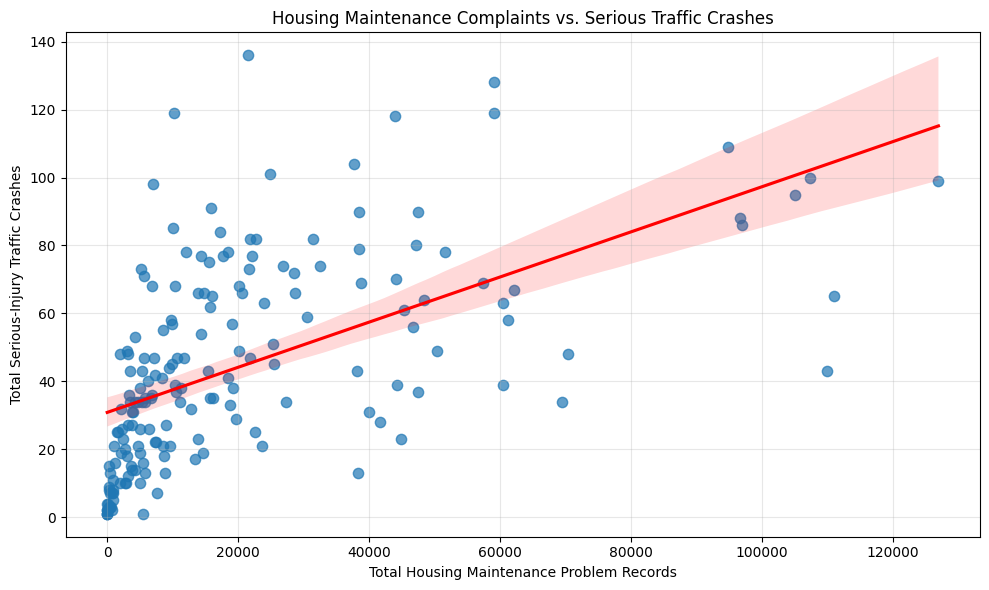

Pearson correlation: 0.555
Spearman correlation: 0.72
Matched areas: 181


In [61]:
# RQ1: Final Scatter Plot

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_q1,
    x="total_problem_records",
    y="total_serious_crashes",
    scatter_kws={"alpha": 0.7, "s": 55},
    line_kws={"color": "red"}
)

plt.title(
    "Housing Maintenance Complaints vs. Serious Traffic Crashes"
)
plt.xlabel("Total Housing Maintenance Problem Records")
plt.ylabel("Total Serious-Injury Traffic Crashes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pearson_corr = df_q1[
    ["total_problem_records", "total_serious_crashes"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = df_q1[
    ["total_problem_records", "total_serious_crashes"]
].corr(method="spearman").iloc[0, 1]

print("Pearson correlation:", round(pearson_corr, 3))
print("Spearman correlation:", round(spearman_corr, 3))
print("Matched areas:", len(df_q1))

Interpretation: The Pearson correlation was 0.555, indicating a moderate positive linear relationship. The Spearman correlation was 0.720, indicating a stronger positive association in the rankings of the areas. Generally, areas with more housing maintenance problem records also tended to have more serious traffic crashes.



RSQ2 :Does the relationship between housing maintenance complaints and serious traffic crashes differ across NYC's five boroughs?

In [62]:
#- Research Question 2
# Compare the relationship between housing complaints
# and serious traffic crashes across NYC boroughs

# Ensure numeric columns
df_q1["total_problem_records"] = pd.to_numeric(
    df_q1["total_problem_records"], errors="coerce"
)

df_q1["total_serious_crashes"] = pd.to_numeric(
    df_q1["total_serious_crashes"], errors="coerce"
)

# Remove invalid observations
df_q2 = df_q1.dropna(
    subset=[
        "borough_clean",
        "total_problem_records",
        "total_serious_crashes"
    ]
).copy()

# Calculate correlations separately for each borough
borough_results = []

for borough, group in df_q2.groupby("borough_clean"):

    pearson = group[
        ["total_problem_records", "total_serious_crashes"]
    ].corr(method="pearson").iloc[0, 1]

    spearman = group[
        ["total_problem_records", "total_serious_crashes"]
    ].corr(method="spearman").iloc[0, 1]

    borough_results.append({
        "borough": borough,
        "matched_areas": len(group),
        "total_housing_problems": group[
            "total_problem_records"
        ].sum(),
        "total_serious_crashes": group[
            "total_serious_crashes"
        ].sum(),
        "pearson_correlation": pearson,
        "spearman_correlation": spearman
    })

df_q2_results = pd.DataFrame(borough_results)

print("RQ2 borough analysis:")
display(
    df_q2_results.sort_values(
        "spearman_correlation",
        ascending=False
    ).round(3)
)

RQ2 borough analysis:


,borough,matched_areas,total_housing_problems,total_serious_crashes,pearson_correlation,spearman_correlation
3,QUEENS,60,461881,1904,0.659,0.703
0,BRONX,25,1274756,1522,0.716,0.678
2,MANHATTAN,47,791259,1697,0.300,0.568
1,BROOKLYN,38,1069391,2596,0.391,0.446
4,STATEN ISLAND,11,61279,296,0.463,0.328


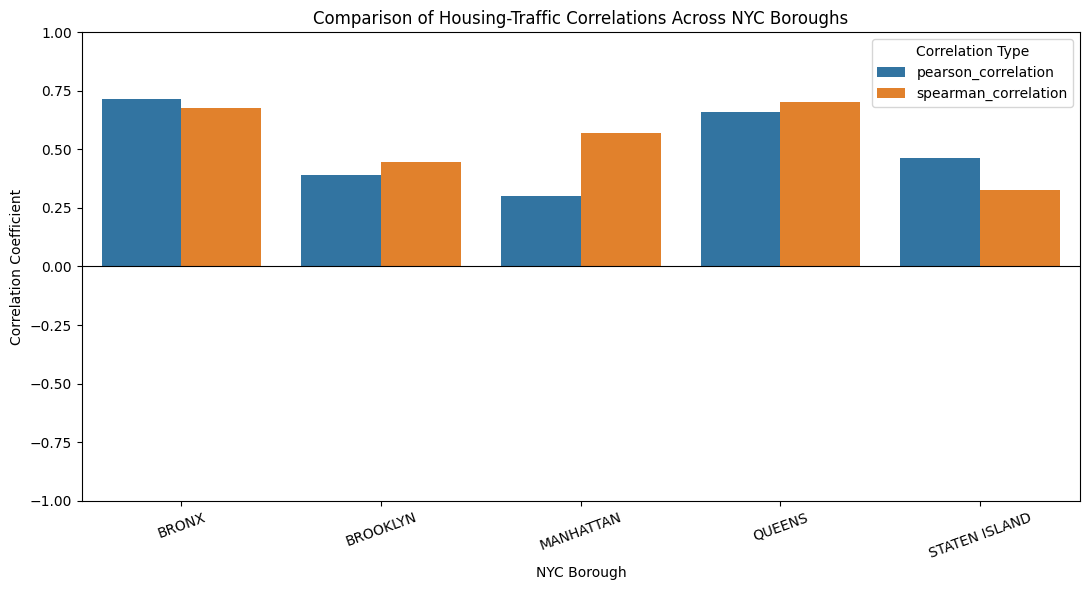

,borough,matched_areas,total_housing_problems,total_serious_crashes,pearson_correlation,spearman_correlation
0,BRONX,25,1274756,1522,0.716,0.678
1,BROOKLYN,38,1069391,2596,0.391,0.446
2,MANHATTAN,47,791259,1697,0.300,0.568
3,QUEENS,60,461881,1904,0.659,0.703
4,STATEN ISLAND,11,61279,296,0.463,0.328


In [63]:
#  - RQ2: Compare Correlations

plt.figure(figsize=(11, 6))

df_plot = df_q2_results.melt(
    id_vars="borough",
    value_vars=[
        "pearson_correlation",
        "spearman_correlation"
    ],
    var_name="correlation_type",
    value_name="correlation"
)

sns.barplot(
    data=df_plot,
    x="borough",
    y="correlation",
    hue="correlation_type"
)

plt.title(
    "Comparison of Housing-Traffic Correlations Across NYC Boroughs"
)
plt.xlabel("NYC Borough")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=20)
plt.ylim(-1, 1)
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(title="Correlation Type")
plt.tight_layout()
plt.show()

display(df_q2_results.round(3))

Interpretation: The Bronx recorded the highest Pearson correlation (0.716), while Queens recorded the highest Spearman correlation (0.703). Brooklyn showed weaker positive correlations (0.391 Pearson and 0.446 Spearman). Manhattan had a relatively low Pearson correlation (0.300), but a higher Spearman correlation (0.568). Staten Island had correlations of 0.463 and 0.328, respectively, based on only 11 matched areas.

# AI Prompt — Karim's Contribution

I am working on a Data Engineering and Visualization project analyzing two NYC datasets:

1. Housing Maintenance Code Complaints and Problems.
2. SIRTA Serious-Injury Traffic Crash Data.

My responsibility is to complete two research questions that investigate meaningful relationships between these datasets.

## Research Question 1
Do NYC ZIP-code areas with higher numbers of housing maintenance complaints also experience higher numbers of serious-injury traffic crashes?

- Aggregate both datasets by ZIP code and borough.
- Use the shared analysis period, January 2022 to June 2026.
- Match areas represented in both datasets.
- Calculate Pearson and Spearman correlations.
- Create a scatter plot with a regression line.
- Interpret the actual correlation results and chart.

## Research Question 2
Does the relationship between housing maintenance complaints and serious traffic crashes differ across NYC's five boroughs?

- Separate the matched areas by borough.
- Calculate Pearson and Spearman correlations for each borough.
- Create visualizations comparing the five boroughs.
- Explain the differences using the actual results.
- Consider the number of matched areas in each borough when interpreting the findings.

## Requirements
- Use the existing cleaned and integrated project data.
- Do not invent results, statistics, or conclusions.
- Do not claim that correlation proves causation.
- Clearly distinguish serious-injury crashes from all traffic crashes.
- Explain the methodology, objective, visualization, interpretation, conclusion, and limitations for each question.
- Keep the analysis reproducible and use clear, properly labeled visualizations.
- Preserve the existing project work and avoid unnecessarily repeating completed data preparation.

Research question: Do monthly changes in housing maintenance complaint activity correspond to changes in serious-injury traffic crashes across NYC?

In [64]:

# RQ3
# Prepare citywide monthly data

import pandas as pd
import numpy as np

# 1. Prepare monthly housing complaint totals
df_housing_agg["problem_records"] = pd.to_numeric(
    df_housing_agg["problem_records"],
    errors="coerce"
)

housing_monthly = (
    df_housing_agg
    .groupby(["year", "month"], as_index=False)
    .agg(
        housing_problems=("problem_records", "sum")
    )
)

# 2. Prepare monthly serious-injury traffic crash totals
df_transport_full["crash_date"] = pd.to_datetime(
    df_transport_full["crash_date"],
    errors="coerce"
)

transport_period = df_transport_full[
    df_transport_full["crash_date"].between(
        "2022-01-01", "2026-06-30"
    )
].copy()

transport_period["year"] = transport_period["crash_date"].dt.year
transport_period["month"] = transport_period["crash_date"].dt.month

transport_monthly = (
    transport_period
    .groupby(["year", "month"], as_index=False)
    .agg(
        serious_crashes=("open_data_crash_id", "nunique")
    )
)

# 3. Combine the two monthly datasets
df_q3 = pd.merge(
    housing_monthly,
    transport_monthly,
    on=["year", "month"],
    how="outer",
    validate="one_to_one"
)

# 4. Create a complete monthly timeline
all_months = pd.date_range(
    start="2022-01-01",
    end="2026-06-01",
    freq="MS"
)

df_q3["date"] = pd.to_datetime(
    df_q3["year"].astype("Int64").astype(str)
    + "-"
    + df_q3["month"].astype("Int64").astype(str)
    + "-01",
    errors="coerce"
)

df_q3 = (
    df_q3
    .set_index("date")
    .reindex(all_months)
    .rename_axis("date")
    .reset_index()
)

# 5. Fill months without source records and calculate changes
df_q3[["housing_problems", "serious_crashes"]] = (
    df_q3[["housing_problems", "serious_crashes"]]
    .fillna(0)
)

df_q3["housing_change"] = df_q3["housing_problems"].diff()
df_q3["crash_change"] = df_q3["serious_crashes"].diff()

print("RQ3 monthly dataset shape:", df_q3.shape)
display(df_q3.head(12))
display(df_q3.tail(12))


RQ3 monthly dataset shape: (54, 7)


,date,year,month,housing_problems,serious_crashes,housing_change,crash_change
0,2022-01-01,2022,1,104553,171,NaN,NaN
1,2022-02-01,2022,2,65791,164,-38762.0,-7.0
2,2022-03-01,2022,3,61838,206,-3953.0,42.0
3,2022-04-01,2022,4,50330,164,-11508.0,-42.0
4,2022-05-01,2022,5,40747,262,-9583.0,98.0
5,2022-06-01,2022,6,37833,277,-2914.0,15.0
6,2022-07-01,2022,7,41000,331,3167.0,54.0
7,2022-08-01,2022,8,42194,293,1194.0,-38.0
8,2022-09-01,2022,9,41233,267,-961.0,-26.0
9,2022-10-01,2022,10,66112,262,24879.0,-5.0


,date,year,month,housing_problems,serious_crashes,housing_change,crash_change
42,2025-07-01,2025,7,52231,306,5244.0,34.0
43,2025-08-01,2025,8,46964,279,-5267.0,-27.0
44,2025-09-01,2025,9,48773,310,1809.0,31.0
45,2025-10-01,2025,10,81377,285,32604.0,-25.0
46,2025-11-01,2025,11,92525,220,11148.0,-65.0
47,2025-12-01,2025,12,111900,212,19375.0,-8.0
48,2026-01-01,2026,1,135239,183,23339.0,-29.0
49,2026-02-01,2026,2,112871,156,-22368.0,-27.0
50,2026-03-01,2026,3,82796,206,-30075.0,50.0
51,2026-04-01,2026,4,70082,207,-12714.0,1.0


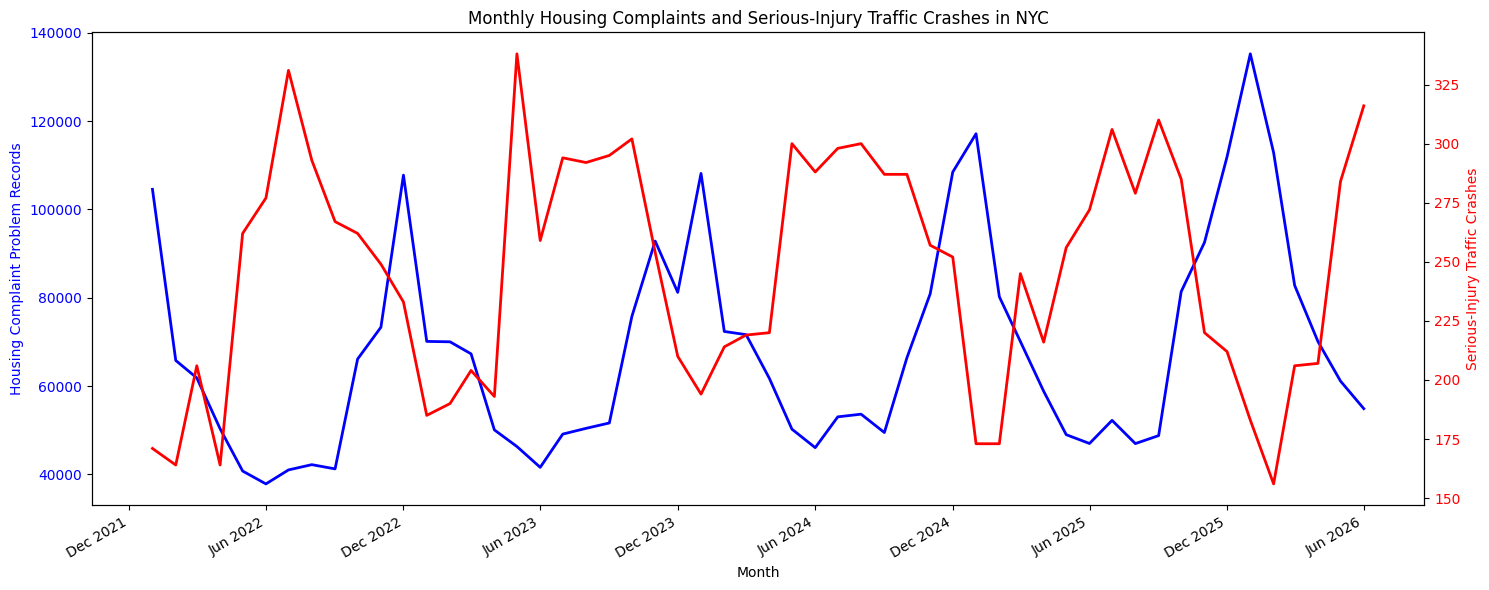

In [65]:

#  RQ3
#  Monthly trend visualization

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    df_q3["date"],
    df_q3["housing_problems"],
    color="blue",
    linewidth=2,
    label="Housing Problems"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Housing Complaint Problem Records", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()

ax2.plot(
    df_q3["date"],
    df_q3["serious_crashes"],
    color="red",
    linewidth=2,
    label="Serious-Injury Traffic Crashes"
)

ax2.set_ylabel("Serious-Injury Traffic Crashes", color="red")
ax2.tick_params(axis="y", labelcolor="red")

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.title(
    "Monthly Housing Complaints and Serious-Injury Traffic Crashes in NYC"
)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()


In [66]:

#  - RQ3
#: Statistical analysis

# Correlation between monthly totals
pearson_totals = df_q3[
    ["housing_problems", "serious_crashes"]
].corr(method="pearson").iloc[0, 1]

spearman_totals = df_q3[
    ["housing_problems", "serious_crashes"]
].corr(method="spearman").iloc[0, 1]

# Correlation between month-to-month changes
change_data = df_q3[
    ["housing_change", "crash_change"]
].dropna()

pearson_changes = change_data.corr(
    method="pearson"
).iloc[0, 1]

spearman_changes = change_data.corr(
    method="spearman"
).iloc[0, 1]

print("RQ3 RESULTS")
print("------------------------------")
print("Number of months:", len(df_q3))
print("Pearson correlation (monthly totals):", round(pearson_totals, 3))
print("Spearman correlation (monthly totals):", round(spearman_totals, 3))
print("Pearson correlation (monthly changes):", round(pearson_changes, 3))
print("Spearman correlation (monthly changes):", round(spearman_changes, 3))


RQ3 RESULTS
------------------------------
Number of months: 54
Pearson correlation (monthly totals): -0.59
Spearman correlation (monthly totals): -0.584
Pearson correlation (monthly changes): -0.175
Spearman correlation (monthly changes): -0.167


interpreation: The monthly totals show a moderately strong negative correlation. This means that months with higher housing complaint activity tended to have fewer serious-injury traffic crashes, and vice versa.

However, the relationship between month-to-month changes is weakly negative. This suggests that increases or decreases in housing complaints do not closely correspond to changes in serious traffic crashes.

RQ4: Are ZIP–borough areas with consistently high housing complaint activity also associated with consistently high serious traffic crash activity across years?

In [67]:

# RQ4 -Prepare yearly data

import pandas as pd
import numpy as np

# Work with complete years only
housing_source = df_housing_final.copy()
transport_source = df_transport_final.copy()

housing_source["year"] = pd.to_numeric(
    housing_source["year"], errors="coerce"
)

transport_source["year"] = pd.to_numeric(
    transport_source["year"], errors="coerce"
)

housing_source = housing_source[
    housing_source["year"].between(2022, 2025)
].copy()

transport_source = transport_source[
    transport_source["year"].between(2022, 2025)
].copy()

# Standardize integration keys
for df in [housing_source, transport_source]:
    df["zip_clean"] = df["zip_clean"].astype(str).str.strip()
    df["borough_clean"] = (
        df["borough_clean"].astype(str).str.strip().str.upper()
    )

# Convert measures to numeric
housing_source["problem_records"] = pd.to_numeric(
    housing_source["problem_records"], errors="coerce"
)

transport_source["serious_crashes"] = pd.to_numeric(
    transport_source["serious_crashes"], errors="coerce"
)

# Aggregate housing complaints by area and year
housing_yearly = (
    housing_source
    .groupby(
        ["zip_clean", "borough_clean", "year"],
        as_index=False
    )
    .agg(
        annual_housing_problems=("problem_records", "sum")
    )
)

# Aggregate serious crashes by area and year
transport_yearly = (
    transport_source
    .groupby(
        ["zip_clean", "borough_clean", "year"],
        as_index=False
    )
    .agg(
        annual_serious_crashes=("serious_crashes", "sum")
    )
)

# Keep only area-year combinations found in both datasets
df_q4 = pd.merge(
    housing_yearly,
    transport_yearly,
    on=["zip_clean", "borough_clean", "year"],
    how="inner",
    validate="one_to_one"
)

print("RQ4 dataset shape:", df_q4.shape)
print("Years included:", sorted(df_q4["year"].unique()))
print("Matched ZIP-borough-year observations:", len(df_q4))
print("Matched areas:", df_q4.groupby(
    ["zip_clean", "borough_clean"]
).ngroups)

display(df_q4.head(10))


RQ4 dataset shape: (653, 5)
Years included: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Matched ZIP-borough-year observations: 653
Matched areas: 177


,zip_clean,borough_clean,year,annual_housing_problems,annual_serious_crashes
0,10001,MANHATTAN,2022,1076,7
1,10001,MANHATTAN,2023,1089,24
2,10001,MANHATTAN,2024,1448,16
3,10001,MANHATTAN,2025,1277,18
4,10002,MANHATTAN,2022,4371,4
5,10002,MANHATTAN,2023,3561,25
6,10002,MANHATTAN,2024,3572,26
7,10002,MANHATTAN,2025,3441,17
8,10003,MANHATTAN,2022,3346,2
9,10003,MANHATTAN,2023,3034,12


In [68]:

# RQ4 -: Analyze yearly rankings

# Calculate percentile ranks within each year
df_q4["housing_rank"] = (
    df_q4.groupby("year")["annual_housing_problems"]
    .rank(pct=True)
)

df_q4["crash_rank"] = (
    df_q4.groupby("year")["annual_serious_crashes"]
    .rank(pct=True)
)

# Identify areas in the top 25% for both measures
df_q4["high_housing"] = df_q4["housing_rank"] >= 0.75
df_q4["high_crashes"] = df_q4["crash_rank"] >= 0.75

df_q4["high_in_both"] = (
    df_q4["high_housing"] & df_q4["high_crashes"]
)

# Summarize each ZIP-borough area across years
df_q4_summary = (
    df_q4
    .groupby(["zip_clean", "borough_clean"], as_index=False)
    .agg(
        years_observed=("year", "nunique"),
        average_housing_rank=("housing_rank", "mean"),
        average_crash_rank=("crash_rank", "mean"),
        years_high_in_both=("high_in_both", "sum")
    )
)

df_q4_summary["average_combined_rank"] = (
    df_q4_summary["average_housing_rank"]
    + df_q4_summary["average_crash_rank"]
) / 2

df_q4_summary = df_q4_summary.sort_values(
    "average_combined_rank",
    ascending=False
)

# Correlation across matched area-year observations
pearson_yearly = df_q4[
    ["annual_housing_problems", "annual_serious_crashes"]
].corr(method="pearson").iloc[0, 1]

spearman_yearly = df_q4[
    ["annual_housing_problems", "annual_serious_crashes"]
].corr(method="spearman").iloc[0, 1]

print("RQ4 RESULTS")
print("------------------------------")
print("Matched observations:", len(df_q4))
print("Matched areas:", len(df_q4_summary))
print("Pearson correlation:", round(pearson_yearly, 3))
print("Spearman correlation:", round(spearman_yearly, 3))

print("\nAreas with the most years in the top 25% for both:")
display(
    df_q4_summary.sort_values(
        ["years_high_in_both", "average_combined_rank"],
        ascending=False
    ).head(15)
)


RQ4 RESULTS
------------------------------
Matched observations: 653
Matched areas: 177
Pearson correlation: 0.404
Spearman correlation: 0.486

Areas with the most years in the top 25% for both:


,zip_clean,borough_clean,years_observed,average_housing_rank,average_crash_rank,years_high_in_both,average_combined_rank
59,10456,BRONX,4,0.962967,0.956515,4,0.959741
70,10467,BRONX,4,0.985487,0.918407,4,0.951947
60,10457,BRONX,4,0.978564,0.891159,4,0.934862
98,11212,BROOKLYN,4,0.913824,0.923884,4,0.918854
89,11203,BROOKLYN,4,0.843358,0.948136,4,0.895747
115,11230,BROOKLYN,4,0.796182,0.960299,4,0.878240
112,11226,BROOKLYN,4,0.998555,0.870482,3,0.934518
71,10468,BRONX,4,0.963295,0.846281,3,0.904788
93,11207,BROOKLYN,4,0.910346,0.888281,3,0.899314
56,10453,BRONX,4,0.965461,0.789905,3,0.877683


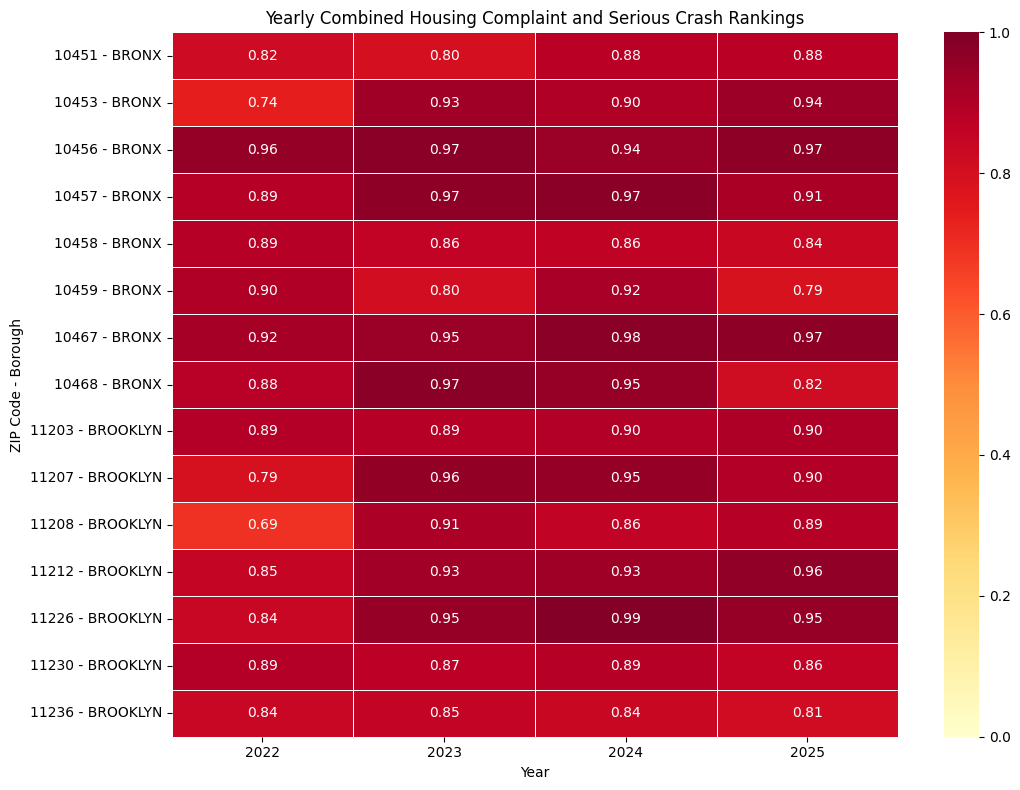

In [69]:

# RQ4 -: Yearly consistency heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Select the 15 areas with the highest average combined ranking
top_areas = df_q4_summary.head(15)[
    ["zip_clean", "borough_clean"]
]

df_q4_top = df_q4.merge(
    top_areas,
    on=["zip_clean", "borough_clean"],
    how="inner"
).copy()

df_q4_top["area"] = (
    df_q4_top["zip_clean"].astype(str)
    + " - "
    + df_q4_top["borough_clean"]
)

# Calculate the average of the two yearly percentile ranks
df_q4_top["combined_rank"] = (
    df_q4_top["housing_rank"]
    + df_q4_top["crash_rank"]
) / 2

heatmap_data = df_q4_top.pivot(
    index="area",
    columns="year",
    values="combined_rank"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title(
    "Yearly Combined Housing Complaint and Serious Crash Rankings"
)
plt.xlabel("Year")
plt.ylabel("ZIP Code - Borough")
plt.tight_layout()
plt.show()


Interpretation
The results show a moderate positive relationship between annual housing complaint activity and serious-injury traffic crashes across matched ZIP–borough areas.

The Pearson correlation (0.404) indicates a moderate positive linear relationship, while the Spearman correlation (0.486) suggests that areas with higher housing complaint rankings also tend to have higher serious crash rankings.

The heatmap shows that several areas maintained high combined rankings throughout all four years (2022–2025). For example:
- 10456 – Bronx: ranked in the top 25% for both measures in all four years.
- 10467 – Bronx: ranked in the top 25% for both measures in all four years.
- 10457 – Bronx: ranked in the top 25% for both measures in all four years.
- 11212 – Brooklyn: ranked in the top 25% for both measures in all four years.
This suggests that some areas consistently experience relatively high levels of both housing complaints and serious-injury traffic crashes.

AI Prompting Documentation — RQ3 and RQ4 Abdelrahman

RQ3 — Monthly Housing Complaints and Serious-Injury Traffic Crashes

Research Question:

Do monthly changes in housing maintenance complaint activity correspond to changes in serious-injury traffic crashes across NYC?

AI Prompt / Instructions:

Act as a data analysis assistant working with the NYC Housing Maintenance Code Complaints dataset and the SIRTA serious-injury traffic crashes dataset.

Prepare a monthly analysis covering January 2022 to June 2026.

Requirements:

Aggregate housing complaint problem records by year and month.

Aggregate serious-injury traffic crashes by year and month using unique crash IDs.

Combine both datasets using year and month.

Create a complete monthly timeline covering the analysis period.

Calculate month-to-month changes in both datasets.

Create a dual-axis line chart to compare monthly housing complaints and serious-injury traffic crashes.

Calculate Pearson and Spearman correlations for monthly totals and monthly changes.

Present the actual statistical results and avoid unsupported conclusions.

Analysis Results:

Pearson correlation (monthly totals): -0.590

Spearman correlation (monthly totals): -0.584

Pearson correlation (monthly changes): -0.175

Spearman correlation (monthly changes): -0.167

Main Finding:

Monthly totals showed a moderate negative relationship, while month-to-month changes showed a weak negative relationship.

RQ4 — Consistent Housing Complaint and Serious Crash Activity Across Areas

Research Question:

Are ZIP–borough areas with consistently high housing complaint activity also associated with consistently high serious traffic crash activity across years?

AI Prompt / Instructions:

Analyze the relationship between annual housing complaint activity and serious-injury traffic crashes across NYC ZIP–borough areas.

Use the complete years 2022–2025.

Requirements:

Aggregate housing complaint records by ZIP code, borough, and year.

Aggregate serious-injury traffic crashes by the same geographic and temporal fields.

Integrate the datasets using ZIP code, borough, and year.

Keep matched ZIP–borough–year observations for the comparison.

Calculate yearly percentile rankings for housing complaints and serious crashes.

Identify areas that rank in the top 25% for both measures.

Calculate how many years each area remains in the top 25% for both measures.

Calculate Pearson and Spearman correlations across matched observations.

Create a heatmap showing the yearly combined rankings of the 15 highest-ranked areas.

Interpret the results using the actual outputs, without claiming causation.

Analysis Results:

Matched observations: 653

Matched ZIP–borough areas: 177

Pearson correlation: 0.404

Spearman correlation: 0.486

Examples of Consistently High-Ranking Areas:

10456 — Bronx: top 25% in both measures in all four years.

10467 — Bronx: top 25% in both measures in all four years.

10457 — Bronx: top 25% in both measures in all four years.

11212 — Brooklyn: top 25% in both measures in all four years.

Main Finding:

The analysis showed a moderate positive relationship between annual housing complaint activity and serious-injury traffic crashes. Several areas maintained high relative rankings in both measures throughout 2022–2025.

General Instructions Followed

Use the selected project datasets as the main data sources.

Use actual notebook variables and outputs.

Do not invent results or statistics.

Use visualizations that directly address each research question.

Explain findings in simple, clear language.

Distinguish correlation from causation.

Include limitations where relevant.

Use only the available data and analysis period.

Keep code organized and understandable.

RS5 : Do seasonal patterns in housing maintenance complaint activity align with seasonal patterns in serious-injury traffic crashes across NYC boroughs?

In [70]:

# RQ5 - Step 54: Prepare seasonal data

import pandas as pd
import numpy as np

# Copy the prepared datasets
housing_source = df_housing_final.copy()
transport_source = df_transport_final.copy()

# Keep complete years only
housing_source["year"] = pd.to_numeric(
    housing_source["year"], errors="coerce"
)

transport_source["year"] = pd.to_numeric(
    transport_source["year"], errors="coerce"
)

housing_source = housing_source[
    housing_source["year"].between(2022, 2025)
].copy()

transport_source = transport_source[
    transport_source["year"].between(2022, 2025)
].copy()

# Convert measures to numeric
housing_source["problem_records"] = pd.to_numeric(
    housing_source["problem_records"], errors="coerce"
)

transport_source["serious_crashes"] = pd.to_numeric(
    transport_source["serious_crashes"], errors="coerce"
)

# Aggregate both datasets by borough, year, and month
housing_monthly = (
    housing_source
    .groupby(["borough_clean", "year", "month"], as_index=False)
    .agg(
        housing_problems=("problem_records", "sum")
    )
)

transport_monthly = (
    transport_source
    .groupby(["borough_clean", "year", "month"], as_index=False)
    .agg(
        serious_crashes=("serious_crashes", "sum")
    )
)

# Integrate the monthly data
df_q5 = pd.merge(
    housing_monthly,
    transport_monthly,
    on=["borough_clean", "year", "month"],
    how="outer",
    validate="one_to_one"
)

# Assign each month to a season
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df_q5["season"] = df_q5["month"].apply(get_season)

# Fill missing measures for absent borough-month groups
df_q5[["housing_problems", "serious_crashes"]] = (
    df_q5[["housing_problems", "serious_crashes"]].fillna(0)
)

# Calculate average seasonal activity across the four years
seasonal_summary = (
    df_q5
    .groupby(["borough_clean", "season"], as_index=False)
    .agg(
        average_housing_problems=("housing_problems", "mean"),
        average_serious_crashes=("serious_crashes", "mean")
    )
)

season_order = ["Winter", "Spring", "Summer", "Autumn"]

seasonal_summary["season"] = pd.Categorical(
    seasonal_summary["season"],
    categories=season_order,
    ordered=True
)

seasonal_summary = seasonal_summary.sort_values(
    ["borough_clean", "season"]
)

print("RQ5 seasonal dataset shape:", df_q5.shape)
print("Years included:", sorted(df_q5["year"].unique()))

display(seasonal_summary)


RQ5 seasonal dataset shape: (240, 6)
Years included: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,borough_clean,season,average_housing_problems,average_serious_crashes
3,BRONX,Winter,32976.333333,23.500000
1,BRONX,Spring,19522.000000,25.583333
2,BRONX,Summer,16222.416667,29.416667
0,BRONX,Autumn,23119.833333,33.583333
7,BROOKLYN,Winter,25620.583333,41.000000
5,BROOKLYN,Spring,16479.083333,41.666667
6,BROOKLYN,Summer,14040.000000,48.583333
4,BROOKLYN,Autumn,20114.833333,58.583333
11,MANHATTAN,Winter,19763.250000,23.166667
9,MANHATTAN,Spring,12354.583333,24.666667


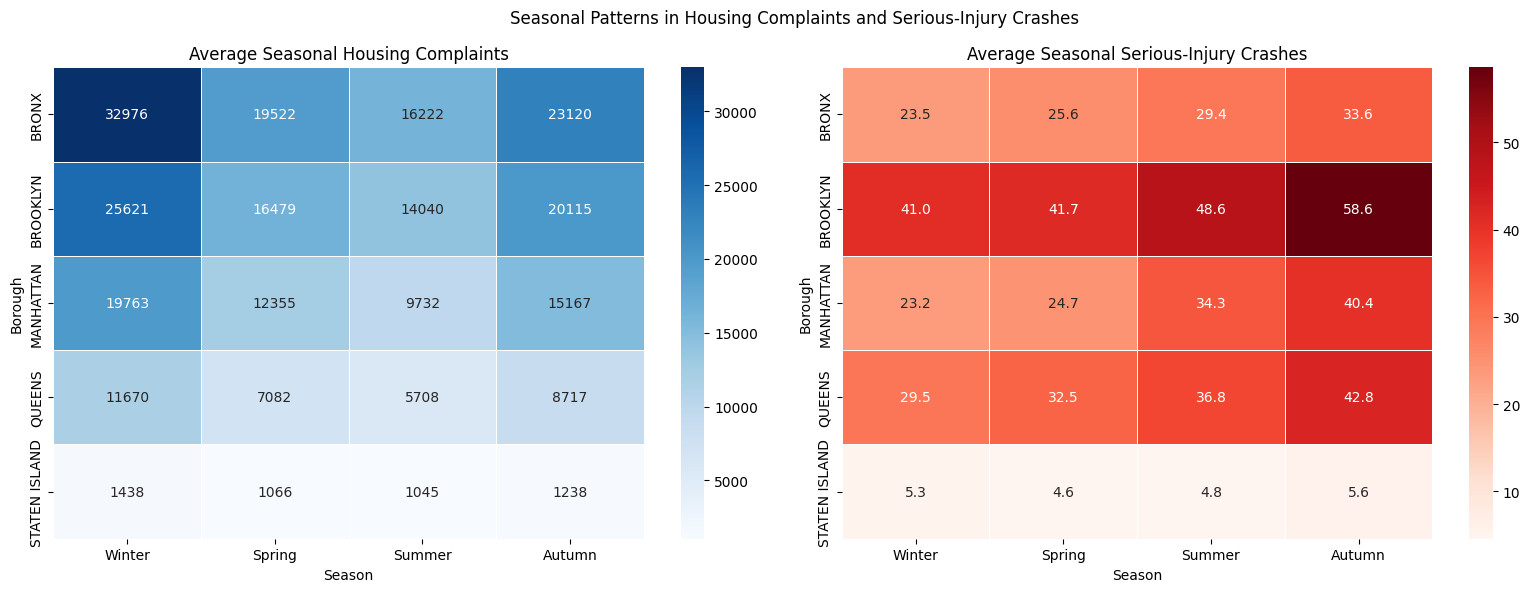

In [72]:

# RQ5 - : Seasonal comparison heatmaps

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Housing complaints heatmap
housing_pivot = seasonal_summary.pivot(
    index="borough_clean",
    columns="season",
    values="average_housing_problems"
)

sns.heatmap(
    housing_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Average Seasonal Housing Complaints")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Borough")

# Serious-injury crashes heatmap
crash_pivot = seasonal_summary.pivot(
    index="borough_clean",
    columns="season",
    values="average_serious_crashes"
)

sns.heatmap(
    crash_pivot,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Average Seasonal Serious-Injury Crashes")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Borough")

plt.suptitle(
    "Seasonal Patterns in Housing Complaints and Serious-Injury Crashes"
)

plt.tight_layout()
plt.show()


RQ5 — Interpretation
The visualizations show that housing complaint activity and serious-injury traffic crashes follow different seasonal patterns across all five NYC boroughs.
- Bronx: Housing complaints peak in winter (32,976), while serious crashes peak in autumn (33.6).
- Brooklyn: Housing complaints peak in winter (25,621), while serious crashes peak in autumn (58.6).
- Manhattan: Housing complaints peak in winter (19,763), while serious crashes peak in autumn (40.4).
- Queens: Housing complaints peak in winter (11,670), while serious crashes peak in autumn (42.8).
- Staten Island: Housing complaints peak in winter (1,438), while serious crashes peak in autumn (5.6).

Are NYC ZIP–borough areas with higher housing maintenance complaint activity also associated with greater serious traffic crash severity, measured by severe injuries and fatalities per serious-injury crash?

In [73]:

# RQ6 Prepare housing and crash severity data

import pandas as pd
import numpy as np

# Copy the prepared datasets
housing_source = df_housing_final.copy()
transport_source = df_transport_final.copy()

# Convert measures to numeric
housing_source["problem_records"] = pd.to_numeric(
    housing_source["problem_records"],
    errors="coerce"
)

for column in ["serious_crashes", "severe_injuries", "fatalities"]:
    transport_source[column] = pd.to_numeric(
        transport_source[column],
        errors="coerce"
    )

# Aggregate housing complaints by ZIP and borough
housing_area = (
    housing_source
    .groupby(["zip_clean", "borough_clean"], as_index=False)
    .agg(
        total_housing_problems=("problem_records", "sum")
    )
)

# Aggregate serious crashes and severity outcomes
transport_area = (
    transport_source
    .groupby(["zip_clean", "borough_clean"], as_index=False)
    .agg(
        total_serious_crashes=("serious_crashes", "sum"),
        total_severe_injuries=("severe_injuries", "sum"),
        total_fatalities=("fatalities", "sum")
    )
)

# Match the two datasets
df_q6 = pd.merge(
    housing_area,
    transport_area,
    on=["zip_clean", "borough_clean"],
    how="inner",
    validate="one_to_one"
)

# Calculate severity outcomes per serious crash
df_q6["severe_injuries_per_crash"] = (
    df_q6["total_severe_injuries"]
    / df_q6["total_serious_crashes"].replace(0, np.nan)
)

df_q6["fatalities_per_crash"] = (
    df_q6["total_fatalities"]
    / df_q6["total_serious_crashes"].replace(0, np.nan)
)

df_q6["severity_outcomes_per_crash"] = (
    df_q6["total_severe_injuries"]
    + df_q6["total_fatalities"]
) / df_q6["total_serious_crashes"].replace(0, np.nan)

print("RQ6 dataset shape:", df_q6.shape)
print("Matched ZIP-borough areas:", len(df_q6))

display(df_q6.head(10))


RQ6 dataset shape: (181, 9)
Matched ZIP-borough areas: 181


,zip_clean,borough_clean,total_housing_problems,total_serious_crashes,total_severe_injuries,total_fatalities,severe_injuries_per_crash,fatalities_per_crash,severity_outcomes_per_crash
0,10001,MANHATTAN,5647,71,71.0,3.0,1.000000,0.042254,1.042254
1,10002,MANHATTAN,17298,84,81.0,8.0,0.964286,0.095238,1.059524
2,10003,MANHATTAN,15764,62,60.0,4.0,0.967742,0.064516,1.032258
3,10004,MANHATTAN,263,9,9.0,0.0,1.000000,0.000000,1.000000
4,10005,MANHATTAN,663,2,2.0,0.0,1.000000,0.000000,1.000000
5,10006,MANHATTAN,564,3,3.0,0.0,1.000000,0.000000,1.000000
6,10007,MANHATTAN,320,15,16.0,0.0,1.066667,0.000000,1.066667
7,10009,MANHATTAN,19246,38,33.0,5.0,0.868421,0.131579,1.000000
8,10010,MANHATTAN,5683,47,50.0,1.0,1.063830,0.021277,1.085106
9,10011,MANHATTAN,11669,47,46.0,2.0,0.978723,0.042553,1.021277


In [75]:

# RQ6 -: Statistical analysis

correlation_data = df_q6[
    [
        "total_housing_problems",
        "severity_outcomes_per_crash"
    ]
].dropna()

pearson_severity = correlation_data.corr(
    method="pearson"
).iloc[0, 1]

spearman_severity = correlation_data.corr(
    method="spearman"
).iloc[0, 1]

print("RQ6 RESULTS")
print("------------------------------")
print("Matched areas:", len(correlation_data))
print(
    "Pearson correlation:",
    round(pearson_severity, 3)
)
print(
    "Spearman correlation:",
    round(spearman_severity, 3)
)

print("\nSeverity summary:")
display(
    df_q6[
        [
            "total_housing_problems",
            "total_serious_crashes",
            "total_severe_injuries",
            "total_fatalities",
            "severity_outcomes_per_crash"
        ]
    ].describe()
)


RQ6 RESULTS
------------------------------
Matched areas: 181
Pearson correlation: 0.028
Spearman correlation: 0.255

Severity summary:


,total_housing_problems,total_serious_crashes,total_severe_injuries,total_fatalities,severity_outcomes_per_crash
count,181.000000,181.000000,181.000000,181.000000,181.000000
mean,20213.071823,44.281768,44.966851,2.944751,1.077491
std,25107.313500,30.074780,30.996935,2.491594,0.086462
min,1.000000,1.000000,1.000000,0.000000,1.000000
25%,3765.000000,21.000000,20.000000,1.000000,1.022222
50%,10198.000000,39.000000,38.000000,2.000000,1.055556
75%,25359.000000,66.000000,69.000000,4.000000,1.106061
max,126939.000000,136.000000,144.000000,14.000000,1.750000


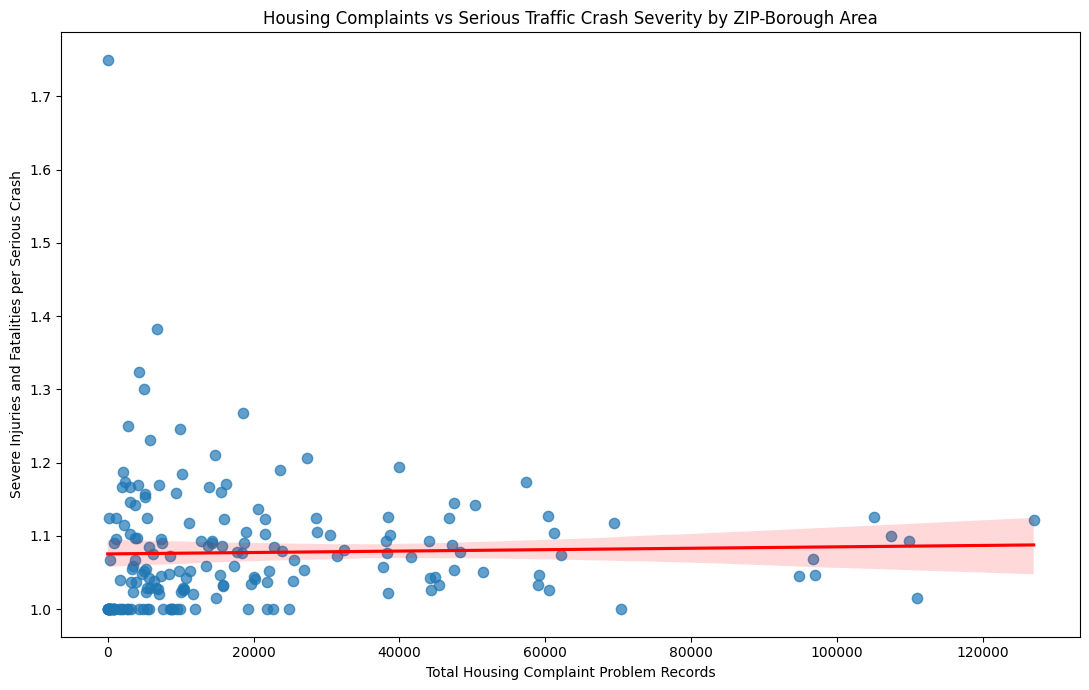

In [77]:

# RQ6 - : Housing complaints and crash severity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.regplot(
    data=df_q6,
    x="total_housing_problems",
    y="severity_outcomes_per_crash",
    scatter_kws={"alpha": 0.7, "s": 55},
    line_kws={"color": "red"}
)

plt.title(
    "Housing Complaints vs Serious Traffic Crash Severity by ZIP-Borough Area"
)

plt.xlabel("Total Housing Complaint Problem Records")
plt.ylabel("Severe Injuries and Fatalities per Serious Crash")

plt.tight_layout()
plt.show()


Interpretation
The Pearson correlation of 0.028 indicates almost no linear relationship between housing complaint counts and crash severity.

The Spearman correlation of 0.255 indicates a weak positive ranking relationship. This suggests that areas with higher housing complaint activity may tend to have slightly higher crash severity rankings, but the association is limited.

The scatter plot supports this finding because the regression line is almost flat, and most areas are concentrated around 1.0–1.2 severe injuries and fatalities per serious crash.

# AI Prompting Documentation — ZIAD RQ5 and RQ6

## RQ5 — Seasonal Patterns in Housing Complaints and Serious-Injury Crashes

**Research Question:**

Do seasonal patterns in housing maintenance complaint activity align with seasonal patterns in serious-injury traffic crashes across NYC boroughs?

**AI Prompt / Instructions:**

Act as a data analysis assistant working with the NYC Housing Maintenance Code Complaints dataset and the SIRTA serious-injury traffic crashes dataset.

Analyze seasonal patterns across the five NYC boroughs using complete years 2022–2025.

Requirements:
1. Aggregate housing complaint problem records by borough, year, and month.
2. Aggregate serious-injury traffic crashes by the same fields.
3. Integrate both datasets using borough, year, and month.
4. Assign months to Winter, Spring, Summer, and Autumn.
5. Calculate average seasonal activity for housing complaints and serious-injury crashes in each borough.
6. Create two heatmaps to compare the seasonal patterns.
7. Interpret the results using actual output values.
8. Identify whether the seasonal peaks align or differ.
9. Include relevant limitations and avoid causal claims.

**Main Findings:**
- Housing complaint activity peaked in winter in all five boroughs.
- Serious-injury traffic crashes peaked in autumn in all five boroughs.
- The two datasets therefore showed different seasonal patterns.

## RQ6 — Housing Complaints and Traffic Crash Severity

**Research Question:**

Are NYC ZIP–borough areas with higher housing maintenance complaint activity also associated with greater serious traffic crash severity, measured by severe injuries and fatalities per serious-injury crash?

**AI Prompt / Instructions:**

Analyze the relationship between housing complaint activity and serious traffic crash severity across matched NYC ZIP–borough areas.

Requirements:
1. Aggregate housing complaint problem records by ZIP code and borough.
2. Aggregate serious crashes, severe injuries, and fatalities by the same geographic fields.
3. Integrate the two datasets using ZIP code and borough.
4. Calculate severe injuries and fatalities per serious crash.
5. Calculate Pearson and Spearman correlations between housing complaint totals and the severity measure.
6. Create a scatter plot with a regression line.
7. Present the actual statistical results and descriptive statistics.
8. Interpret the relationship without claiming causation.

**Analysis Results:**
- Matched ZIP–borough areas: 181
- Pearson correlation: 0.028
- Spearman correlation: 0.255
- Average severity outcomes per serious crash: approximately 1.08

**Main Finding:**

The analysis showed almost no linear relationship and a weak positive ranking relationship between housing complaint activity and serious traffic crash severity.

## General Instructions

- Use the selected project datasets as the main sources.
- Use actual notebook variables and outputs.
- Do not invent statistics or findings.
- Use visualizations that directly address each research question.
- Explain findings in clear language.
- Distinguish correlation from causation.
- Include limitations relevant to the analysis.

Q7: Are higher housing maintenance complaint levels in one month associated with higher serious-injury traffic crash counts in the following month across NYC?

In [78]:

# RQ7: Prepare one-month lag analysis

import pandas as pd
import numpy as np

# Copy the monthly dataset and sort chronologically
df_q7 = df_q3[
    ["date", "housing_problems", "serious_crashes"]
].copy()

df_q7["date"] = pd.to_datetime(df_q7["date"])

df_q7 = df_q7.sort_values("date").reset_index(drop=True)

# Convert measures to numeric
df_q7["housing_problems"] = pd.to_numeric(
    df_q7["housing_problems"],
    errors="coerce"
)

df_q7["serious_crashes"] = pd.to_numeric(
    df_q7["serious_crashes"],
    errors="coerce"
)

# Compare previous month's housing complaints
# with the following month's serious crashes
df_q7["previous_month_housing"] = (
    df_q7["housing_problems"].shift(1)
)

# Remove the first month because it has no previous month
df_q7 = df_q7.dropna(
    subset=[
        "previous_month_housing",
        "serious_crashes"
    ]
).copy()

print("RQ7 dataset shape:", df_q7.shape)
print("Analysis period:", df_q7["date"].min(), "to", df_q7["date"].max())

display(df_q7.head(10))


RQ7 dataset shape: (53, 4)
Analysis period: 2022-02-01 00:00:00 to 2026-06-01 00:00:00


,date,housing_problems,serious_crashes,previous_month_housing
1,2022-02-01,65791,164,104553.0
2,2022-03-01,61838,206,65791.0
3,2022-04-01,50330,164,61838.0
4,2022-05-01,40747,262,50330.0
5,2022-06-01,37833,277,40747.0
6,2022-07-01,41000,331,37833.0
7,2022-08-01,42194,293,41000.0
8,2022-09-01,41233,267,42194.0
9,2022-10-01,66112,262,41233.0
10,2022-11-01,73313,249,66112.0


In [79]:

# RQ7 - Statistical analysis

pearson_lag = df_q7[
    ["previous_month_housing", "serious_crashes"]
].corr(method="pearson").iloc[0, 1]

spearman_lag = df_q7[
    ["previous_month_housing", "serious_crashes"]
].corr(method="spearman").iloc[0, 1]

print("RQ7 RESULTS")
print("------------------------------")
print("Matched monthly observations:", len(df_q7))
print("Pearson correlation:", round(pearson_lag, 3))
print("Spearman correlation:", round(spearman_lag, 3))


RQ7 RESULTS
------------------------------
Matched monthly observations: 53
Pearson correlation: -0.8
Spearman correlation: -0.785


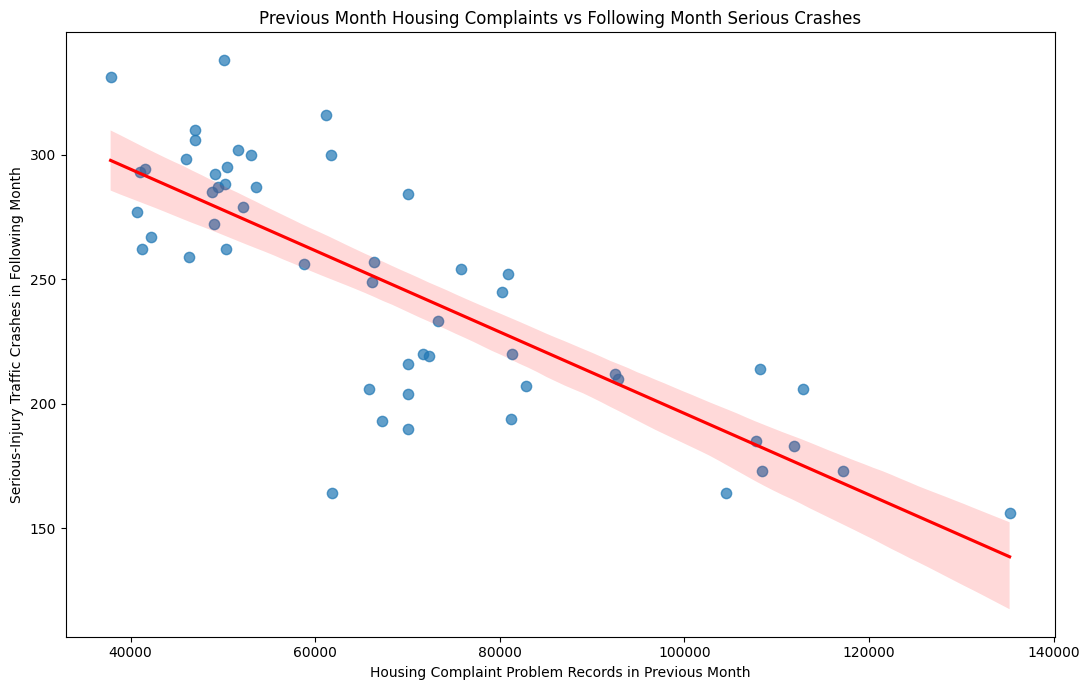

In [80]:

# RQ7 -Lagged relationship visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.regplot(
    data=df_q7,
    x="previous_month_housing",
    y="serious_crashes",
    scatter_kws={"alpha": 0.7, "s": 55},
    line_kws={"color": "red"}
)

plt.title(
    "Previous Month Housing Complaints vs Following Month Serious Crashes"
)

plt.xlabel("Housing Complaint Problem Records in Previous Month")
plt.ylabel("Serious-Injury Traffic Crashes in Following Month")

plt.tight_layout()
plt.show()


Interpretation
The Pearson correlation of -0.800 indicates a strong negative linear relationship. The Spearman correlation of -0.785 also indicates a strong negative association in rankings.

The scatter plot supports these results: as housing complaint records in the previous month increase, serious-injury traffic crashes in the following month generally decrease.

This suggests that higher housing complaint activity in one month does not correspond to higher serious-injury crash activity in the following month.

Are NYC ZIP–borough areas with more housing problem records per unique complaint also associated with higher numbers of serious-injury traffic crashes?

In [81]:

# RQ8 -: Prepare complaint complexity data

import pandas as pd
import numpy as np

df_q8 = df_q1.copy()

# Convert measures to numeric
numeric_columns = [
    "total_problem_records",
    "total_unique_complaints",
    "total_serious_crashes"
]

for column in numeric_columns:
    df_q8[column] = pd.to_numeric(
        df_q8[column],
        errors="coerce"
    )

# Calculate housing problem records per unique complaint
df_q8["problems_per_complaint"] = (
    df_q8["total_problem_records"]
    / df_q8["total_unique_complaints"].replace(0, np.nan)
)

# Remove invalid observations
df_q8 = df_q8.dropna(
    subset=[
        "problems_per_complaint",
        "total_serious_crashes"
    ]
)

print("RQ8 dataset shape:", df_q8.shape)
print("Matched ZIP-borough areas:", len(df_q8))

display(
    df_q8[
        [
            "zip_clean",
            "borough_clean",
            "total_problem_records",
            "total_unique_complaints",
            "problems_per_complaint",
            "total_serious_crashes"
        ]
    ].head(10)
)


RQ8 dataset shape: (181, 8)
Matched ZIP-borough areas: 181


,zip_clean,borough_clean,total_problem_records,total_unique_complaints,problems_per_complaint,total_serious_crashes
0,10001,MANHATTAN,5647,3669,1.539111,71
1,10002,MANHATTAN,17298,11906,1.452881,84
2,10003,MANHATTAN,15764,11419,1.380506,62
3,10004,MANHATTAN,263,181,1.453039,9
4,10005,MANHATTAN,663,394,1.682741,2
5,10006,MANHATTAN,564,416,1.355769,3
6,10007,MANHATTAN,320,249,1.285141,15
7,10009,MANHATTAN,19246,13591,1.416084,38
8,10010,MANHATTAN,5683,4191,1.356001,47
9,10011,MANHATTAN,11669,7930,1.471501,47


In [82]:

# RQ8 -: Calculate correlations

correlation_data = df_q8[
    ["problems_per_complaint", "total_serious_crashes"]
].dropna()

pearson_q8 = correlation_data.corr(
    method="pearson"
).iloc[0, 1]

spearman_q8 = correlation_data.corr(
    method="spearman"
).iloc[0, 1]

print("RQ8 RESULTS")
print("------------------------------")
print("Matched areas:", len(correlation_data))
print("Pearson correlation:", round(pearson_q8, 3))
print("Spearman correlation:", round(spearman_q8, 3))

print("\nDescriptive statistics:")
display(
    df_q8[
        [
            "problems_per_complaint",
            "total_serious_crashes"
        ]
    ].describe()
)


RQ8 RESULTS
------------------------------
Matched areas: 181
Pearson correlation: 0.232
Spearman correlation: 0.223

Descriptive statistics:


,problems_per_complaint,total_serious_crashes
count,181.000000,181.000000
mean,1.583820,44.281768
std,0.207027,30.074780
min,1.000000,1.000000
25%,1.452881,21.000000
50%,1.584617,39.000000
75%,1.724334,66.000000
max,2.167930,136.000000


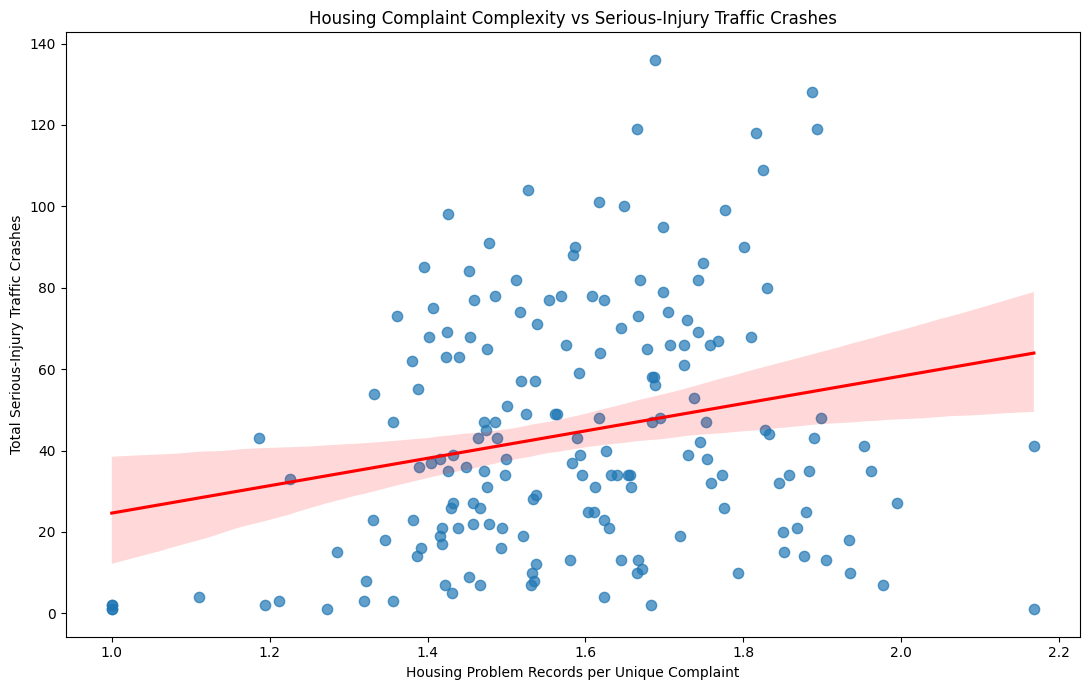

In [83]:

# RQ8 -: Complaint complexity vs serious crashes

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.regplot(
    data=df_q8,
    x="problems_per_complaint",
    y="total_serious_crashes",
    scatter_kws={"alpha": 0.7, "s": 55},
    line_kws={"color": "red"}
)

plt.title(
    "Housing Complaint Complexity vs Serious-Injury Traffic Crashes"
)

plt.xlabel("Housing Problem Records per Unique Complaint")
plt.ylabel("Total Serious-Injury Traffic Crashes")

plt.tight_layout()
plt.show()


Interpretation
The results show a weak positive relationship between housing complaint complexity and serious-injury traffic crashes across 181 matched ZIP–borough areas.

The Pearson correlation of 0.232 indicates a weak positive linear relationship, while the Spearman correlation of 0.223 indicates a weak positive association in rankings.

The scatter plot shows a slight upward trend, suggesting that areas with more housing problem records per unique complaint tend to have somewhat higher serious-injury crash counts. However, the points are widely distributed, indicating that the relationship is limited.

The average number of housing problem records per unique complaint was approximately 1.58, while the average number of serious-injury crashes per matched area was approximately 44.

# AI Prompting Documentation — Youssef RQ7 and RQ8

## RQ7 — Previous-Month Housing Complaints and Following-Month Serious Crashes

**Research Question:**

Are higher housing maintenance complaint levels in one month associated with higher serious-injury traffic crash counts in the following month across NYC?

**AI Prompt / Instructions:**

Analyze the possible one-month delayed relationship between housing maintenance complaints and serious-injury traffic crashes in NYC.

Requirements:
1. Use the monthly housing and transportation data covering January 2022 to June 2026.
2. Sort the monthly records chronologically.
3. Shift housing complaint counts by one month to compare the previous month's housing activity with the following month's serious-injury crashes.
4. Exclude the first month because it has no previous-month value.
5. Calculate Pearson and Spearman correlations.
6. Create a scatter plot with a regression line.
7. Interpret the actual correlation results and visualization.
8. Explain limitations and avoid claiming causation.

**Analysis Results:**
- Matched monthly observations: 53
- Pearson correlation: -0.800
- Spearman correlation: -0.785

**Main Finding:**

The analysis showed a strong negative association between housing complaint activity in the previous month and serious-injury traffic crashes in the following month.

## RQ8 — Housing Complaint Complexity and Serious-Injury Traffic Crashes

**Research Question:**

Are NYC ZIP–borough areas with more housing problem records per unique complaint also associated with higher numbers of serious-injury traffic crashes?

**AI Prompt / Instructions:**

Analyze the relationship between housing complaint complexity and serious-injury traffic crashes across matched NYC ZIP–borough areas.

Requirements:
1. Aggregate housing problem records and unique complaints by ZIP code and borough.
2. Aggregate serious-injury traffic crashes by the same geographic fields.
3. Integrate both datasets using ZIP code and borough.
4. Calculate housing problem records per unique complaint.
5. Calculate Pearson and Spearman correlations between complaint complexity and serious-injury crash counts.
6. Create a scatter plot with a regression line.
7. Present descriptive statistics and actual results.
8. Interpret the relationship and explain the limitations without claiming causation.

**Analysis Results:**
- Matched ZIP–borough areas: 181
- Pearson correlation: 0.232
- Spearman correlation: 0.223
- Average problem records per unique complaint: approximately 1.58
- Average serious-injury crashes per area: approximately 44

**Main Finding:**

The analysis showed a weak positive association between housing complaint complexity and serious-injury traffic crash counts.

## General Instructions

- Use the selected project datasets as the main sources.
- Use actual notebook data and outputs.
- Do not invent findings or statistics.
- Use visualizations that directly address each research question.
- Explain findings in clear language.
- Distinguish correlation from causation.
- Include relevant limitations.
- Preserve the correct analysis period and geographic integration level.

# Overall AI Prompt — NYC Housing and Transportation Data Analysis

Act as an expert data engineer and data visualization analyst. Help develop a complete Data Engineering and Visualization project using two NYC Open Data datasets:

**Housing dataset:** NYC Housing Maintenance Code Complaints and Problems  
**Dataset ID:** `ygpa-z7cr`

**Transportation dataset:** SIRTA Serious-Injury Traffic Crashes  
**Dataset ID:** `xeqp-qz8h`

The objective is to investigate meaningful relationships between housing maintenance complaints and serious-injury traffic crashes in New York City.

## 1. Dataset Exploration and Preparation

- Load both selected datasets from NYC Open Data.
- Explore their dimensions, columns, data types, and date coverage.
- Identify relevant geographic and temporal attributes.
- Investigate missing values, duplicates, invalid values, outliers, and inconsistent categories.
- Standardize dates, borough names, and ZIP codes.
- Explain all cleaning and exclusion decisions.
- Do not invent or silently correct missing geographic information.

## 2. Data Integration

- Integrate the datasets using meaningful geographic and temporal attributes.
- Use ZIP code, borough, year, and month where appropriate.
- Explain the chosen integration granularity.
- Avoid assuming that ZIP codes always belong to only one borough.
- Validate the integration keys and duplicate records.
- Perform post-integration cleaning.
- Explain unmatched records and distinguish missing observations from genuine zero-event observations.
- Preserve the limitations of the source datasets.

## 3. Research Questions and Visualizations

Develop eight meaningful cross-domain research questions. Each question must investigate a relationship between housing complaints and serious-injury traffic crashes and have its own visualization.

### RQ1 — Housing Complaints and Serious Traffic Crashes

Do NYC ZIP-code areas with higher numbers of housing maintenance complaints also experience higher numbers of serious-injury traffic crashes?

- Use a scatter plot and regression line.
- Calculate Pearson and Spearman correlations.
- Explain the strength and direction of the relationship.

### RQ2 — Differences Across Boroughs

Does the relationship between housing maintenance complaints and serious traffic crashes differ across NYC's five boroughs?

- Compare the relationship separately for each borough.
- Use borough-level scatter plots and comparisons.
- Explain differences and sample-size limitations.

### RQ3 — Monthly Changes

Do monthly changes in housing maintenance complaint activity correspond to changes in serious-injury traffic crashes across NYC?

- Compare monthly housing and transportation totals.
- Use a monthly trend visualization.
- Calculate correlations between monthly totals and month-to-month changes.
- Explain the observed relationship.

### RQ4 — Consistency Across Years

Are ZIP–borough areas with consistently high housing complaint activity also associated with consistently high serious traffic crash activity across years?

- Compare complete years 2022–2025.
- Calculate yearly percentile rankings.
- Identify areas repeatedly ranking in the top 25% for both measures.
- Use a yearly combined-ranking heatmap.
- Calculate Pearson and Spearman correlations.

### RQ5 — Seasonal Patterns

Do seasonal patterns in housing maintenance complaint activity align with seasonal patterns in serious-injury traffic crashes across NYC boroughs?

- Compare Winter, Spring, Summer, and Autumn.
- Calculate average seasonal activity by borough.
- Use two heatmaps to compare both datasets.
- Identify whether seasonal peaks align or differ.

### RQ6 — Crash Severity

Are NYC ZIP–borough areas with higher housing maintenance complaint activity also associated with greater serious traffic crash severity, measured by severe injuries and fatalities per serious-injury crash?

- Calculate severe injuries and fatalities per serious crash.
- Compare the severity measure with housing complaint totals.
- Calculate Pearson and Spearman correlations.
- Use a scatter plot with a regression line.

### RQ7 — One-Month Lag

Are higher housing maintenance complaint levels in one month associated with higher serious-injury traffic crash counts in the following month across NYC?

- Shift monthly housing complaint counts by one month.
- Compare previous-month housing activity with following-month crash counts.
- Calculate Pearson and Spearman correlations.
- Use a scatter plot with a regression line.
- Avoid interpreting a lagged correlation as proof of causation.

### RQ8 — Housing Complaint Complexity

Are NYC ZIP–borough areas with more housing problem records per unique complaint also associated with higher numbers of serious-injury traffic crashes?

- Calculate housing problem records per unique complaint.
- Compare the ratio with total serious-injury crashes by ZIP–borough area.
- Calculate Pearson and Spearman correlations.
- Use a scatter plot with a regression line.
- Explain that the ratio measures recorded problem entries, not actual housing-condition severity.

## 4. Statistical Analysis and Interpretation

For every research question:

- Use actual calculated results.
- Select a visualization that directly answers the question.
- Interpret the direction and strength of the relationship.
- Explain important patterns and differences.
- Include relevant limitations.
- Avoid unsupported conclusions and causal claims.
- Never invent statistics or findings.

Use clear, understandable language suitable for an academic project.

## 5. Notebook Requirements

Organize the notebook into clear sections:

1. Project introduction and objectives.
2. Dataset selection and overview.
3. Data loading.
4. Exploratory data analysis.
5. Pre-integration cleaning.
6. Data integration.
7. Post-integration cleaning and validation.
8. Eight research questions and their visualizations.
9. Interpretations and limitations.
10. AI prompts used throughout the project.
11. Dataset links and references.

Use descriptive variable names, organized code, and comments for complex operations.

## 6. Website Requirements

Build an interactive website that presents the integrated datasets and the project's findings.

The website should include:

- Multiple dropdown filters, including borough, year, housing category, and transportation category where supported by the data.
- Natural-language search that applies relevant filters.
- A central Generate Report button that updates the displayed charts.
- Multiple visualization types.
- Interactive charts with hover, zoom, and filtering where supported.
- At least one direct cross-domain visualization.
- A data story section containing the research question, findings, limitations, and potential benefit to NYC.
- A consistent design and responsive interface.
- Free deployment where possible.

## 7. Documentation and Submission

Prepare:
- The complete Jupyter/Colab notebook.
- Actual AI prompting documentation.
- A README containing setup instructions, deployment instructions, and team contributions.
- Full website source code.
- GitHub repository.
- Deployed website link.
- Dataset links.

Clearly document each team member's individual research questions, visualizations, cleaning tasks, integration work, website components, and other contributions.

## Final Instructions

Work step by step and do not skip project requirements.

Do not invent data, prompts, outputs, or implementation status. Distinguish completed work from proposed work. Preserve the source datasets' limitations and ensure all conclusions are supported by actual analysis.

## Dataset Links and Sources

**Housing Dataset:** NYC Housing Maintenance Code Complaints and Problems  
Dataset ID: `ygpa-z7cr`  
Link: https://data.cityofnewyork.us/resource/ygpa-z7cr

**Transportation Dataset:** SIRTA Serious-Injury Traffic Crashes  
Dataset ID: `xeqp-qz8h`  
Link: https://data.cityofnewyork.us/resource/xeqp-qz8h

**Source:** NYC Open Data

In [84]:

# Export processed datasets for the Streamlit website

import os

os.makedirs("website_data", exist_ok=True)

# Main integrated dataset
df_integrated.to_csv(
    "website_data/integrated_data.csv",
    index=False
)

# Research question datasets
df_q1.to_csv("website_data/rq1_data.csv", index=False)
df_q3.to_csv("website_data/rq3_data.csv", index=False)
df_q4.to_csv("website_data/rq4_data.csv", index=False)
df_q5.to_csv("website_data/rq5_data.csv", index=False)
df_q6.to_csv("website_data/rq6_data.csv", index=False)
df_q7.to_csv("website_data/rq7_data.csv", index=False)
df_q8.to_csv("website_data/rq8_data.csv", index=False)

print("All available datasets exported successfully!")


All available datasets exported successfully!


In [85]:

import shutil
from google.colab import files

shutil.make_archive(
    "website_data",
    "zip",
    "website_data"
)

files.download("website_data.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>